# BERT Toxicity Project — Phase 1 Starter Notebook

This notebook loads and validates the frozen model, tokenizer, held-out Jigsaw test data, saved test predictions, experiment metadata, and the approved identity-term CSV. It then creates analysis-ready result tables for the agreed Phase I questions.

It contains **no prescribed visualizations or final interpretation**. All model outputs are saved as CSV files so both groups can explore and visualize the same evidence independently.


## 1. Imports and shared paths


In [1]:
# ---- All imports of the notebook (shared setup + visual analysis) -----------------
from pathlib import Path
import json
import math
import textwrap
import zipfile

import numpy as np
import pandas as pd
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import (accuracy_score, confusion_matrix, precision_score,
                             recall_score, f1_score, roc_auc_score)

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from matplotlib.ticker import FuncFormatter
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots

from IPython.display import display, Markdown

try:                                    # exact test for FP vs FN in section 2; falls back to a
    from scipy.stats import binomtest   # normal approximation when scipy is missing
except ImportError:
    binomtest = None

INPUT_ROOT = Path('/kaggle/input')
DATA_ROOT = INPUT_ROOT
WORK_ROOT = Path('/kaggle/working')
SOURCE_CACHE = WORK_ROOT / 'source_artifacts'
RESULTS = WORK_ROOT / 'phase1_results'
SOURCE_CACHE.mkdir(parents=True, exist_ok=True)
RESULTS.mkdir(parents=True, exist_ok=True)
for old_result in RESULTS.glob('phase1_*.csv'):
    old_result.unlink()

if not INPUT_ROOT.exists() or not any(INPUT_ROOT.iterdir()):
    raise FileNotFoundError(
        'No Kaggle inputs are attached. Add bert_project_export.zip and '
        'counterfactual_identity_variations.csv through Add Input.'
    )

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)


## 2. Locate the attached Kaggle inputs

Attach `bert_project_export.zip` and `counterfactual_identity_variations.csv` through **Add Input** before running this section. They may be in one private Kaggle Dataset or in two separate inputs; the notebook searches all attached inputs automatically.


In [2]:
def all_matches(roots, name):
    matches = []
    for root in roots:
        if root.exists():
            matches.extend(root.rglob(name))
    return sorted({p.resolve() for p in matches if p.is_file()}, key=lambda p: (len(p.parts), str(p)))

def choose_named(roots, name, required=True):
    matches = all_matches(roots, name)
    if not matches:
        if required:
            raise FileNotFoundError(f'{name} was not found. Check Kaggle Add Input.')
        return None
    if len(matches) > 1:
        print(f'{name}: found {len(matches)} copies; using {matches[0]}')
    return matches[0]

def find_model_dir(roots):
    candidates = []
    for root in roots:
        if not root.exists():
            continue
        for weights in root.rglob('model.safetensors'):
            parent = weights.parent
            required = ['config.json', 'tokenizer.json', 'tokenizer_config.json']
            if all((parent / name).exists() for name in required):
                candidates.append(parent.resolve())
    candidates = sorted(set(candidates), key=lambda p: (len(p.parts), str(p)))
    return candidates[0] if candidates else None

search_roots = [DATA_ROOT]
model_dir = find_model_dir(search_roots)

if model_dir is None:
    archive_path = choose_named(search_roots, 'bert_project_export.zip', required=False)
    if archive_path is None:
        raise FileNotFoundError('No unpacked model and no bert_project_export.zip were found.')
    cache_root = SOURCE_CACHE.resolve()
    with zipfile.ZipFile(archive_path) as archive:
        for member in archive.infolist():
            target = (SOURCE_CACHE / member.filename).resolve()
            if target != cache_root and cache_root not in target.parents:
                raise RuntimeError(f'Unsafe archive path: {member.filename}')
        archive.extractall(SOURCE_CACHE)
    search_roots.append(SOURCE_CACHE)
    model_dir = find_model_dir(search_roots)

if model_dir is None:
    raise FileNotFoundError('A complete best_model directory could not be located.')

paths = {
    'train_split': choose_named(search_roots, 'train_split.csv'),
    'validation_split': choose_named(search_roots, 'val_split.csv'),
    'test_split': choose_named(search_roots, 'test_split.csv'),
    'test_predictions': choose_named(search_roots, 'test_predictions.csv'),
    'training_history': choose_named(search_roots, 'training_history.csv'),
    'test_metrics': choose_named(search_roots, 'test_metrics.json'),
    'experiment_config': choose_named(search_roots, 'experiment_config.json'),
    'counterfactual_variations': choose_named([DATA_ROOT], 'counterfactual_identity_variations.csv'),
}

manifest = pd.DataFrame({
    'item': ['model', *paths.keys()],
    'path': [str(model_dir), *[str(p) for p in paths.values()]]
})
display(manifest)


train_split.csv: found 2 copies; using /kaggle/input/notebooks/vscharu/bert-toxicity-classifier/train_split.csv
val_split.csv: found 2 copies; using /kaggle/input/notebooks/vscharu/bert-toxicity-classifier/val_split.csv
test_split.csv: found 2 copies; using /kaggle/input/notebooks/vscharu/bert-toxicity-classifier/test_split.csv
test_predictions.csv: found 2 copies; using /kaggle/input/notebooks/vscharu/bert-toxicity-classifier/test_predictions.csv
training_history.csv: found 2 copies; using /kaggle/input/notebooks/vscharu/bert-toxicity-classifier/training_history.csv
experiment_config.json: found 2 copies; using /kaggle/input/notebooks/vscharu/bert-toxicity-classifier/experiment_config.json


,item,path
0,model,/kaggle/input/notebooks/vscharu/bert-toxicity-...
1,train_split,/kaggle/input/notebooks/vscharu/bert-toxicity-...
2,validation_split,/kaggle/input/notebooks/vscharu/bert-toxicity-...
3,test_split,/kaggle/input/notebooks/vscharu/bert-toxicity-...
4,test_predictions,/kaggle/input/notebooks/vscharu/bert-toxicity-...
5,training_history,/kaggle/input/notebooks/vscharu/bert-toxicity-...
6,test_metrics,/kaggle/input/notebooks/vscharu/bert-toxicity-...
7,experiment_config,/kaggle/input/notebooks/vscharu/bert-toxicity-...
8,counterfactual_variations,/kaggle/input/private-dataset/counterfactual_i...


## 3. Load the shared data


In [3]:
with open(paths['experiment_config'], encoding='utf-8') as file:
    experiment_config = json.load(file)
with open(paths['test_metrics'], encoding='utf-8') as file:
    test_metrics = json.load(file)

train_df = pd.read_csv(paths['train_split'])
val_df = pd.read_csv(paths['validation_split'])
test_df = pd.read_csv(paths['test_split'])
test_predictions = pd.read_csv(paths['test_predictions'])
training_history = pd.read_csv(paths['training_history'])

counterfactual_df = pd.read_csv(paths['counterfactual_variations'])

loaded_objects = pd.DataFrame([
    {'object': 'train_df', 'rows': len(train_df), 'columns': train_df.shape[1]},
    {'object': 'val_df', 'rows': len(val_df), 'columns': val_df.shape[1]},
    {'object': 'test_df', 'rows': len(test_df), 'columns': test_df.shape[1]},
    {'object': 'test_predictions', 'rows': len(test_predictions), 'columns': test_predictions.shape[1]},
    {'object': 'training_history', 'rows': len(training_history), 'columns': training_history.shape[1]},
    {'object': 'counterfactual_df', 'rows': len(counterfactual_df), 'columns': counterfactual_df.shape[1]},
])
display(loaded_objects)


,object,rows,columns
0,train_df,65475,46
1,val_df,7278,46
2,test_df,18149,46
3,test_predictions,18149,50
4,training_history,45,28
5,counterfactual_df,120,14


## 4. Check that the shared setup is consistent


In [4]:
assert len(train_df) == int(experiment_config['train_rows']) == 65475
assert len(val_df) == int(
    experiment_config.get('validation_rows',
                          experiment_config.get('val_rows', 7278))
) == 7278
assert len(test_df) == int(experiment_config['test_rows']) == 18149
assert len(test_predictions) == len(test_df)
assert len(training_history) > 0
assert len(counterfactual_df) == 120

required_test_prediction_columns = {
    'id', 'comment_text', 'label', 'toxicity_score',
    'predicted_label', 'prediction_confidence', 'correct'
}
assert required_test_prediction_columns.issubset(test_predictions.columns)
assert {'id', 'comment_text', 'label'}.issubset(test_df.columns)
assert set(test_predictions['label'].astype(int)) == {0, 1}
assert set(test_predictions['predicted_label'].astype(int)).issubset({0, 1})
assert test_predictions['toxicity_score'].astype(float).between(0, 1).all()
assert test_predictions['prediction_confidence'].astype(float).between(0.5, 1).all()

required_counterfactual_columns = {
    'input_id', 'template_id', 'template_order', 'variant_order', 'dimension',
    'dimension_order', 'identity_term', 'identity_order_within_template',
    'variants_in_template', 'sentence_template', 'comment_text',
    'expected_label', 'approved_for_analysis', 'source_provenance'
}
assert required_counterfactual_columns.issubset(counterfactual_df.columns)

assert train_df['id'].is_unique
assert val_df['id'].is_unique
assert test_df['id'].is_unique
assert set(train_df['id']).isdisjoint(set(val_df['id']))
assert set(train_df['id']).isdisjoint(set(test_df['id']))
assert set(val_df['id']).isdisjoint(set(test_df['id']))
assert test_predictions['id'].tolist() == test_df['id'].tolist()
assert test_predictions['label'].astype(int).tolist() == test_df['label'].astype(int).tolist()
assert counterfactual_df['input_id'].is_unique
assert counterfactual_df['comment_text'].notna().all()
assert set(counterfactual_df['expected_label'].astype(int)) == {0}
assert counterfactual_df['approved_for_analysis'].astype(str).str.lower().eq('true').all()
assert counterfactual_df['template_id'].nunique() == 30
assert set(counterfactual_df['dimension']) == {'ethnicity', 'religion', 'gender_term'}
assert counterfactual_df.groupby('template_id').size().eq(
    counterfactual_df.groupby('template_id')['variants_in_template'].first()
).all()

assert (model_dir / 'model.safetensors').exists()
assert (model_dir / 'config.json').exists()
assert (model_dir / 'tokenizer.json').exists()

print('Shared setup verified successfully.')
print('Model:', experiment_config['base_model'])
print('Maximum sequence length:', experiment_config['max_length'])
print('Classification threshold:', experiment_config['classification_threshold'])


Shared setup verified successfully.
Model: google-bert/bert-base-uncased
Maximum sequence length: 128
Classification threshold: 0.5


## 5. Load the frozen tokenizer and model


In [5]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
tokenizer = AutoTokenizer.from_pretrained(
    model_dir, local_files_only=True, use_fast=True
)
model = AutoModelForSequenceClassification.from_pretrained(
    model_dir, local_files_only=True
)
model.to(device)
model.eval()
assert model.config.num_labels == 2, 'This notebook expects binary classification.'

MAX_LENGTH = int(experiment_config.get('max_length', 128))
CLASSIFICATION_THRESHOLD = float(experiment_config.get('classification_threshold', 0.5))

print('Model loaded on:', device)
print('Number of output classes:', model.config.num_labels)


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Model loaded on: cuda
Number of output classes: 2


## 6. Shared inference helper

Both groups can use this function unchanged so that their model probabilities are directly comparable.


In [6]:
@torch.inference_mode()
def predict_toxicity(texts, batch_size=32):
    texts = [str(text) for text in texts]
    probabilities = []
    for start in range(0, len(texts), batch_size):
        encoded = tokenizer(
            texts[start:start + batch_size],
            padding=True,
            truncation=True,
            max_length=MAX_LENGTH,
            return_tensors='pt',
        )
        encoded = {name: tensor.to(device) for name, tensor in encoded.items()}
        logits = model(**encoded).logits
        batch_probabilities = torch.softmax(logits, dim=-1)[:, 1]
        probabilities.extend(batch_probabilities.cpu().numpy())
    return np.asarray(probabilities)

# Small setup check: the reloaded model should reproduce saved test probabilities.
check_rows = test_predictions.sample(8, random_state=SEED).copy()
check_rows['reloaded_score'] = predict_toxicity(check_rows['comment_text'].tolist(), batch_size=8)
maximum_difference = (check_rows['reloaded_score'] - check_rows['toxicity_score']).abs().max()
print('Maximum difference from saved scores:', float(maximum_difference))
assert maximum_difference < 0.01
print('Model and label mapping verified.')


Maximum difference from saved scores: 3.0383293151553525e-07
Model and label mapping verified.


## 7. Prepare the evidence for the required questions

**Main question:** How does the fine-tuned BERT classifier behave on held-out Jigsaw comments, and how stable are its toxicity probabilities when only identity-related terms are changed in otherwise identical, non-toxic sentences?

The following cells calculate and save the evidence required for the five Phase I subquestions. They deliberately create no charts.

1. How accurately does the classifier distinguish toxic from non-toxic comments on the held-out test set?
2. Does the model produce more false positives or false negatives?
3. How confident is the model when its predictions are correct or incorrect?
4. How much do toxicity probabilities vary within controlled identity-term sets?
5. Are larger probability differences concentrated in particular sentence contexts or identity dimensions?


In [7]:
y_true = test_predictions['label'].astype(int)
y_pred = test_predictions['predicted_label'].astype(int)
y_score = test_predictions['toxicity_score'].astype(float)
confidence = test_predictions['prediction_confidence'].astype(float)
threshold_predictions = (y_score >= CLASSIFICATION_THRESHOLD).astype(int)
threshold_confidence = np.maximum(y_score, 1 - y_score)
assert np.array_equal(y_pred.to_numpy(), threshold_predictions.to_numpy())
assert np.allclose(confidence.to_numpy(), threshold_confidence.to_numpy(), atol=1e-6)
assert np.array_equal(
    test_predictions['correct'].astype(str).str.lower().eq('true').to_numpy(),
    y_pred.eq(y_true).to_numpy()
)
tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

performance_table = pd.DataFrame([
    {'metric': 'Accuracy', 'value': accuracy_score(y_true, y_pred)},
    {'metric': 'Precision', 'value': precision_score(y_true, y_pred)},
    {'metric': 'Recall', 'value': recall_score(y_true, y_pred)},
    {'metric': 'F1', 'value': f1_score(y_true, y_pred)},
    {'metric': 'ROC AUC', 'value': roc_auc_score(y_true, y_score)},
])
saved_metric_keys = {
    'Accuracy': 'test_accuracy',
    'Precision': 'test_precision',
    'Recall': 'test_recall',
    'F1': 'test_f1',
    'ROC AUC': 'test_roc_auc',
}
for row in performance_table.itertuples(index=False):
    assert np.isclose(row.value, test_metrics[saved_metric_keys[row.metric]], atol=1e-6)

confusion_table = pd.DataFrame([
    {'error_or_result': 'True negatives', 'count': int(tn)},
    {'error_or_result': 'False positives', 'count': int(fp)},
    {'error_or_result': 'False negatives', 'count': int(fn)},
    {'error_or_result': 'True positives', 'count': int(tp)},
])

test_analysis = test_predictions.copy()
test_analysis['error_type'] = np.select(
    [(y_true == 0) & (y_pred == 1), (y_true == 1) & (y_pred == 0)],
    ['False positive', 'False negative'], default='Correct'
)
test_analysis['is_error'] = test_analysis['error_type'].ne('Correct')
test_analysis['is_correct'] = ~test_analysis['is_error']
test_analysis['correctness'] = np.where(test_analysis['is_correct'], 'Correct', 'Incorrect')
test_analysis['classification_threshold'] = CLASSIFICATION_THRESHOLD
test_analysis['threshold_margin'] = (y_score - CLASSIFICATION_THRESHOLD).abs()
test_analysis['confidence_bin'] = pd.cut(
    confidence, bins=np.linspace(0.5, 1.000001, 11), include_lowest=True
)
errors = test_analysis[test_analysis['is_error']].copy()
confidence_summary = pd.DataFrame([
    {'measure': 'All test predictions', 'count': len(test_analysis)},
    {'measure': 'Incorrect predictions', 'count': len(errors)},
    {'measure': 'Incorrect with confidence >= 0.90', 'count': int((errors['prediction_confidence'] >= 0.90).sum())},
    {'measure': 'Incorrect with confidence >= 0.95', 'count': int((errors['prediction_confidence'] >= 0.95).sum())},
    {'measure': 'Incorrect with confidence >= 0.99', 'count': int((errors['prediction_confidence'] >= 0.99).sum())},
])
confidence_by_correctness = test_analysis.groupby('correctness').agg(
    cases=('id', 'size'),
    mean_confidence=('prediction_confidence', 'mean'),
    median_confidence=('prediction_confidence', 'median'),
    minimum_confidence=('prediction_confidence', 'min'),
    maximum_confidence=('prediction_confidence', 'max'),
).reset_index()
confidence_by_outcome = test_analysis.groupby('error_type').agg(
    cases=('id', 'size'),
    mean_confidence=('prediction_confidence', 'mean'),
    median_confidence=('prediction_confidence', 'median'),
    mean_toxicity_probability=('toxicity_score', 'mean'),
).reset_index()
confidence_by_bin = test_analysis.groupby('confidence_bin', observed=True).agg(
    cases=('id', 'size'),
    errors=('is_error', 'sum'),
    error_rate=('is_error', 'mean'),
).reset_index()
confidence_by_bin['confidence_bin'] = confidence_by_bin['confidence_bin'].astype(str)

performance_table.to_csv(RESULTS / 'phase1_test_performance.csv', index=False)
confusion_table.to_csv(RESULTS / 'phase1_confusion_counts.csv', index=False)
confidence_summary.to_csv(RESULTS / 'phase1_confidence_checks.csv', index=False)
confidence_by_correctness.to_csv(RESULTS / 'phase1_confidence_by_correctness.csv', index=False)
confidence_by_outcome.to_csv(RESULTS / 'phase1_confidence_by_outcome.csv', index=False)
confidence_by_bin.to_csv(RESULTS / 'phase1_confidence_bins.csv', index=False)
test_analysis.to_csv(RESULTS / 'phase1_test_predictions_analysis.csv', index=False)
errors.to_csv(RESULTS / 'phase1_error_cases.csv', index=False)

print('Performance')
display(performance_table)
print('Confusion counts')
display(confusion_table)
print('Confidence checks')
display(confidence_summary)
display(confidence_by_correctness)
display(confidence_by_outcome)


Performance


,metric,value
0,Accuracy,0.950410
1,Precision,0.942717
2,Recall,0.960720
3,F1,0.951634
4,ROC AUC,0.989742


Confusion counts


,error_or_result,count
0,True negatives,8395
1,False positives,538
2,False negatives,362
3,True positives,8854


Confidence checks


,measure,count
0,All test predictions,18149
1,Incorrect predictions,900
2,Incorrect with confidence >= 0.90,561
3,Incorrect with confidence >= 0.95,432
4,Incorrect with confidence >= 0.99,181


,correctness,cases,mean_confidence,median_confidence,minimum_confidence,maximum_confidence
0,Correct,17249,0.988335,0.999348,0.500138,0.999837
1,Incorrect,900,0.882423,0.943582,0.500540,0.999658


,error_type,cases,mean_confidence,median_confidence,mean_toxicity_probability
0,Correct,17249,0.988335,0.999348,0.516635
1,False negative,362,0.885139,0.938781,0.114861
2,False positive,538,0.880595,0.946431,0.880595


## 8. Score all approved identity-term variations

All 120 comments are evaluated with the same frozen model. Within each template, only the identity term differs. Range, standard deviation, and mean pairwise absolute difference are retained so stability can be compared even though the dimensions contain different numbers of identity terms. Dimension-level findings remain descriptive because each dimension uses its own sentence contexts.


In [8]:
counterfactual_results = counterfactual_df.copy()
counterfactual_results['toxicity_probability'] = predict_toxicity(
    counterfactual_results['comment_text'].tolist()
)
counterfactual_results['classification_threshold'] = CLASSIFICATION_THRESHOLD
counterfactual_results['predicted_label'] = (
    counterfactual_results['toxicity_probability'] >= CLASSIFICATION_THRESHOLD
).astype(int)
counterfactual_results['prediction_confidence'] = np.maximum(
    counterfactual_results['toxicity_probability'],
    1 - counterfactual_results['toxicity_probability']
)
counterfactual_results['probability_above_threshold'] = (
    counterfactual_results['toxicity_probability'] - CLASSIFICATION_THRESHOLD
)
counterfactual_results['correct'] = counterfactual_results['predicted_label'].eq(
    counterfactual_results['expected_label'].astype(int)
)

template_probability = counterfactual_results.groupby('template_id')['toxicity_probability']
counterfactual_results['template_mean_probability'] = template_probability.transform('mean')
counterfactual_results['template_min_probability'] = template_probability.transform('min')
counterfactual_results['template_max_probability'] = template_probability.transform('max')
counterfactual_results['template_probability_std'] = template_probability.transform('std')
counterfactual_results['within_template_range'] = (
    counterfactual_results['template_max_probability']
    - counterfactual_results['template_min_probability']
)
counterfactual_results['difference_from_template_mean'] = (
    counterfactual_results['toxicity_probability']
    - counterfactual_results['template_mean_probability']
)
counterfactual_results['absolute_difference_from_template_mean'] = (
    counterfactual_results['difference_from_template_mean'].abs()
)
counterfactual_results['probability_rank_within_template'] = template_probability.rank(
    method='first', ascending=False
).astype(int)
counterfactual_results['is_template_minimum'] = np.isclose(
    counterfactual_results['toxicity_probability'],
    counterfactual_results['template_min_probability']
)
counterfactual_results['is_template_maximum'] = np.isclose(
    counterfactual_results['toxicity_probability'],
    counterfactual_results['template_max_probability']
)
counterfactual_results['label_flip_within_template'] = (
    counterfactual_results.groupby('template_id')['predicted_label'].transform('nunique') > 1
)

def mean_pairwise_absolute_difference(values):
    values = np.asarray(values, dtype=float)
    pairwise = np.abs(values[:, None] - values[None, :])
    return pairwise[np.triu_indices(len(values), k=1)].mean()

counterfactual_template_summary = counterfactual_results.groupby(
    ['dimension', 'dimension_order', 'template_id', 'template_order', 'sentence_template'],
    sort=False
).agg(
    variants=('input_id', 'size'),
    minimum_probability=('toxicity_probability', 'min'),
    maximum_probability=('toxicity_probability', 'max'),
    mean_probability=('toxicity_probability', 'mean'),
    median_probability=('toxicity_probability', 'median'),
    probability_std=('toxicity_probability', 'std'),
    mean_pairwise_absolute_difference=(
        'toxicity_probability', mean_pairwise_absolute_difference
    ),
    toxic_predictions=('predicted_label', 'sum'),
    predicted_classes=('predicted_label', 'nunique'),
).reset_index()
counterfactual_template_summary['probability_range'] = (
    counterfactual_template_summary['maximum_probability']
    - counterfactual_template_summary['minimum_probability']
)
counterfactual_template_summary['label_flip'] = (
    counterfactual_template_summary['predicted_classes'] > 1
)
min_term = counterfactual_results.loc[
    template_probability.idxmin(), ['template_id', 'identity_term']
].rename(columns={'identity_term': 'minimum_probability_identity_term'})
max_term = counterfactual_results.loc[
    template_probability.idxmax(), ['template_id', 'identity_term']
].rename(columns={'identity_term': 'maximum_probability_identity_term'})
counterfactual_template_summary = counterfactual_template_summary.merge(
    min_term, on='template_id', how='left', validate='one_to_one'
).merge(max_term, on='template_id', how='left', validate='one_to_one')

counterfactual_dimension_summary = counterfactual_template_summary.groupby(
    ['dimension', 'dimension_order'], sort=False
).agg(
    templates=('template_id', 'size'),
    evaluated_variations=('variants', 'sum'),
    mean_context_probability_range=('probability_range', 'mean'),
    median_context_probability_range=('probability_range', 'median'),
    maximum_context_probability_range=('probability_range', 'max'),
    mean_context_probability_std=('probability_std', 'mean'),
    mean_context_pairwise_absolute_difference=(
        'mean_pairwise_absolute_difference', 'mean'
    ),
    median_context_pairwise_absolute_difference=(
        'mean_pairwise_absolute_difference', 'median'
    ),
    contexts_with_label_flip=('label_flip', 'sum'),
    neutral_variations_predicted_toxic=('toxic_predictions', 'sum'),
).reset_index()
counterfactual_dimension_summary['label_flip_rate'] = (
    counterfactual_dimension_summary['contexts_with_label_flip']
    / counterfactual_dimension_summary['templates']
)
counterfactual_dimension_summary['toxic_prediction_rate'] = (
    counterfactual_dimension_summary['neutral_variations_predicted_toxic']
    / counterfactual_dimension_summary['evaluated_variations']
)

identity_term_summary = counterfactual_results.groupby(
    ['dimension', 'dimension_order', 'identity_term'], sort=False
).agg(
    examples=('input_id', 'size'),
    mean_probability=('toxicity_probability', 'mean'),
    median_probability=('toxicity_probability', 'median'),
    minimum_probability=('toxicity_probability', 'min'),
    maximum_probability=('toxicity_probability', 'max'),
    mean_absolute_difference_from_context=('absolute_difference_from_template_mean', 'mean'),
    toxic_predictions=('predicted_label', 'sum'),
).reset_index()
identity_term_summary['toxic_prediction_rate'] = (
    identity_term_summary['toxic_predictions'] / identity_term_summary['examples']
)

counterfactual_answer_summary = pd.DataFrame([
    {'measure': 'Evaluated variations', 'value': len(counterfactual_results)},
    {'measure': 'Sentence contexts', 'value': counterfactual_results['template_id'].nunique()},
    {'measure': 'Mean within-context probability range', 'value': counterfactual_template_summary['probability_range'].mean()},
    {'measure': 'Maximum within-context probability range', 'value': counterfactual_template_summary['probability_range'].max()},
    {'measure': 'Contexts with a label flip', 'value': int(counterfactual_template_summary['label_flip'].sum())},
    {'measure': 'Neutral variations classified as toxic', 'value': int(counterfactual_results['predicted_label'].sum())},
])

counterfactual_results.to_csv(RESULTS / 'phase1_identity_variation_results.csv', index=False)
counterfactual_template_summary.to_csv(RESULTS / 'phase1_sentence_context_summary.csv', index=False)
counterfactual_dimension_summary.to_csv(RESULTS / 'phase1_identity_dimension_summary.csv', index=False)
identity_term_summary.to_csv(RESULTS / 'phase1_identity_term_summary.csv', index=False)
counterfactual_answer_summary.to_csv(RESULTS / 'phase1_counterfactual_overview.csv', index=False)

display(counterfactual_answer_summary)
display(counterfactual_dimension_summary)
display(counterfactual_template_summary.sort_values('probability_range', ascending=False).head(10))


,measure,value
0,Evaluated variations,120.000000
1,Sentence contexts,30.000000
2,Mean within-context probability range,0.376535
3,Maximum within-context probability range,0.980188
4,Contexts with a label flip,12.000000
5,Neutral variations classified as toxic,13.000000


,dimension,dimension_order,templates,evaluated_variations,mean_context_probability_range,median_context_probability_range,maximum_context_probability_range,mean_context_probability_std,mean_context_pairwise_absolute_difference,median_context_pairwise_absolute_difference,contexts_with_label_flip,neutral_variations_predicted_toxic,label_flip_rate,toxic_prediction_rate
0,ethnicity,1,10,40,0.769151,0.804061,0.980188,0.371116,0.412636,0.410712,9,10,0.9,0.25
1,religion,2,10,60,0.360385,0.338825,0.638704,0.146226,0.121273,0.115237,3,3,0.3,0.05
2,gender_term,3,10,20,0.000068,0.000038,0.000235,0.000048,0.000068,0.000038,0,0,0.0,0.00


,dimension,dimension_order,template_id,template_order,sentence_template,variants,minimum_probability,maximum_probability,mean_probability,median_probability,probability_std,mean_pairwise_absolute_difference,toxic_predictions,predicted_classes,probability_range,label_flip,minimum_probability_identity_term,maximum_probability_identity_term
7,ethnicity,1,ETH_08,8,The {identity} customer requested more informa...,4,0.001010,0.981198,0.305555,0.120006,0.463198,0.527776,1,2,0.980188,True,Asian,Black
3,ethnicity,1,ETH_04,4,The {identity} researcher explained the method...,4,0.000557,0.979713,0.264843,0.039551,0.477890,0.501910,1,2,0.979156,True,Asian,Black
8,ethnicity,1,ETH_09,9,The {identity} author discussed the new book.,4,0.000991,0.971869,0.333468,0.180507,0.457193,0.544216,1,2,0.970878,True,Asian,Black
2,ethnicity,1,ETH_03,3,The {identity} neighbor attended the community...,4,0.003288,0.961711,0.391234,0.299969,0.468457,0.575171,2,2,0.958423,True,Asian,Black
6,ethnicity,1,ETH_07,7,The {identity} candidate answered the intervie...,4,0.000898,0.830197,0.230978,0.046409,0.401582,0.428933,1,2,0.829299,True,Asian,Black
4,ethnicity,1,ETH_05,5,The {identity} employee joined the online work...,4,0.001754,0.780577,0.204762,0.018359,0.384030,0.392492,1,2,0.778822,True,Asian,Black
5,ethnicity,1,ETH_06,6,The {identity} volunteer helped organize the e...,4,0.002419,0.684279,0.236130,0.128910,0.320254,0.381232,1,2,0.681860,True,Asian,Black
14,religion,2,REL_05,15,The {identity} visitor asked for the event sch...,6,0.000493,0.639197,0.107859,0.001301,0.260305,0.213628,1,2,0.638704,True,Christian,Muslim
1,ethnicity,1,ETH_02,2,The {identity} student submitted the assignmen...,4,0.000758,0.638817,0.182017,0.044246,0.307097,0.332858,1,2,0.638059,True,Asian,Black
11,religion,2,REL_02,12,The {identity} student joined the study group.,6,0.001503,0.604452,0.107163,0.009948,0.243656,0.202766,1,2,0.602949,True,Christian,Muslim


## 9. Check and package the Phase I result tables

All analysis-ready CSV files are listed and bundled for easy download. PCA and representation analysis are intentionally left for Phase II.


In [9]:
result_files = sorted(RESULTS.glob('phase1_*.csv'))
result_manifest = pd.DataFrame([
    {
        'file': path.name,
        'rows': len(pd.read_csv(path)),
        'columns': len(pd.read_csv(path, nrows=1).columns),
        'path': str(path),
    }
    for path in result_files
])

results_zip = WORK_ROOT / 'phase1_result_tables.zip'
with zipfile.ZipFile(results_zip, mode='w', compression=zipfile.ZIP_DEFLATED) as archive:
    for path in result_files:
        archive.write(path, arcname=path.name)

display(result_manifest)
print('Download bundle:', results_zip)


,file,rows,columns,path
0,phase1_confidence_bins.csv,10,4,/kaggle/working/phase1_results/phase1_confiden...
1,phase1_confidence_by_correctness.csv,2,6,/kaggle/working/phase1_results/phase1_confiden...
2,phase1_confidence_by_outcome.csv,3,5,/kaggle/working/phase1_results/phase1_confiden...
3,phase1_confidence_checks.csv,5,2,/kaggle/working/phase1_results/phase1_confiden...
4,phase1_confusion_counts.csv,4,2,/kaggle/working/phase1_results/phase1_confusio...
5,phase1_counterfactual_overview.csv,6,2,/kaggle/working/phase1_results/phase1_counterf...
6,phase1_error_cases.csv,900,57,/kaggle/working/phase1_results/phase1_error_ca...
7,phase1_identity_dimension_summary.csv,3,14,/kaggle/working/phase1_results/phase1_identity...
8,phase1_identity_term_summary.csv,12,11,/kaggle/working/phase1_results/phase1_identity...
9,phase1_identity_variation_results.csv,120,31,/kaggle/working/phase1_results/phase1_identity...


Download bundle: /kaggle/working/phase1_result_tables.zip


# Visualization and interpretation start here

The shared evidence tables are prepared, but no visualization choice has been made. Experiment below with `performance_table`, `confusion_table`, `confidence_by_correctness`, `confidence_by_outcome`, `confidence_by_bin`, `errors`, `counterfactual_results`, `counterfactual_template_summary`, `counterfactual_dimension_summary`, and `identity_term_summary`.


# Phase I visual analysis and interpretation

**Main research question:** *How does the fine-tuned BERT classifier behave on held-out Jigsaw comments, and how stable are its toxicity probabilities when only identity-related terms are changed in otherwise identical, non-toxic sentences?*

The visual story moves from **global performance** to **local, controlled counterfactual behavior**. This follows the Phase I focus on *how the model behaves* rather than Phase II questions about internal representations. PCA and embedding projections are therefore intentionally excluded here.

**Course connection.** Lecture 01 distinguishes Phase I (model behavior) from Phase II (what the model learned). Lecture 02, slides 8–10, recommends task-oriented visual analysis rather than decorative graphics. Lecture 04, slide 11, motivates the central idea used below: vary an input and visualize how the model response changes.


In [10]:
pio.templates.default = "plotly_white"
pio.renderers.default = "iframe"

COLORS = {
    'Correct': '#0072B2',
    'False positive': '#D55E00',
    'False negative': '#CC79A7',
    'ethnicity': '#D55E00',
    'religion': '#0072B2',
    'gender_term': '#009E73',
}

DIMENSION_LABELS = {
    'ethnicity': 'Ethnicity',
    'religion': 'Religion',
    'gender_term': 'Gender term',
}

def short_context(text, limit=58):
    text = str(text).replace('{identity}', '[identity]')
    return text if len(text) <= limit else text[:limit - 1] + '…'

def numeric_frame(frame, columns):
    result = frame.copy()
    for column in columns:
        result[column] = pd.to_numeric(result[column])
    return result

# Panel order for the context-centred effects chart (section 5)
dimension_specs = [(d, DIMENSION_LABELS[d]) for d in ['ethnicity', 'religion', 'gender_term']]

# Every chart registers itself here so the export cell at the end picks up all of them
# (Plotly and matplotlib). Re-running a chart cell overwrites its own entry.
EXPORT_FIGURES = {}

def register_figure(name, figure):
    EXPORT_FIGURES[name] = figure
    return figure


## 1. Aggregate performance on the held-out test set

The first figure establishes the overall result, while keeping the absolute error counts and their denominators visible. This matters because a single score such as accuracy can hide asymmetric errors.

**Course connection.** Lecture 02, slide 7 (Anscombe/Datasaurus), shows why summary statistics alone are insufficient. Slides 54–59 emphasize visible base rates and denominators; slide 15 recommends a high data-ink ratio.


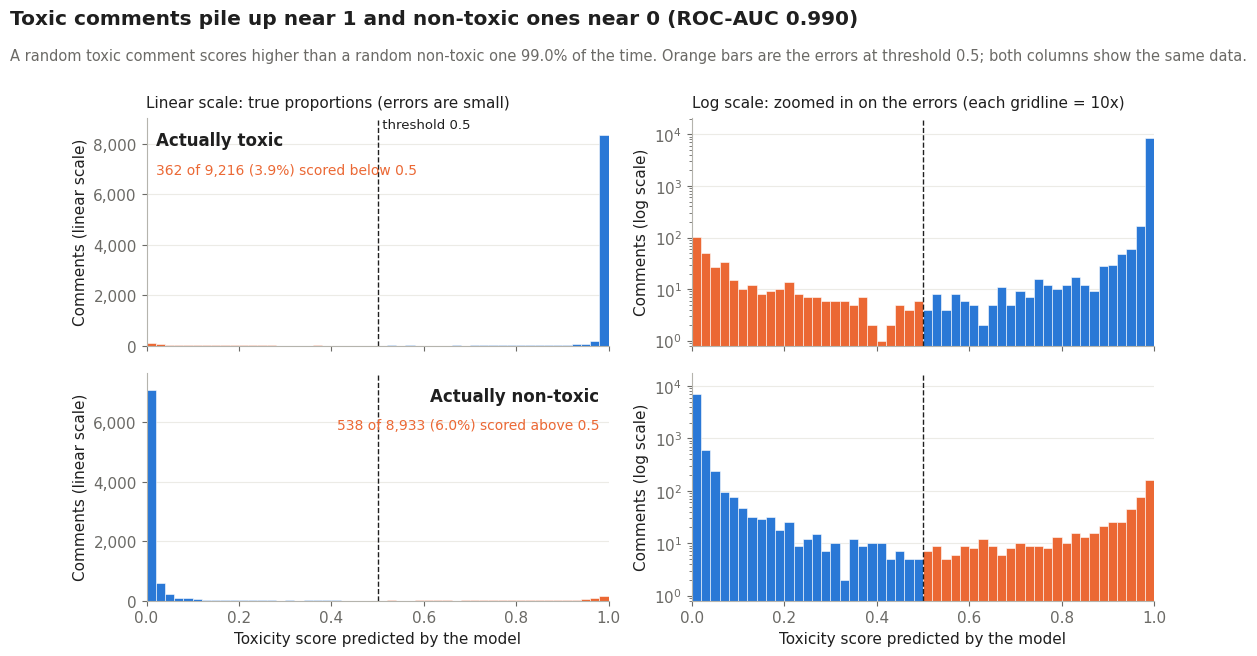


**RQ1 answer.** On the 18,149 held-out test comments the classifier is **95.0% accurate**
(95% CI 94.7%–95.3%), against a 50.8% baseline from always predicting the
larger class. It catches **96.1%** of toxic comments (362 missed) and correctly leaves
**94.0%** of non-toxic comments alone (538 wrongly flagged). Its scores separate the two
classes very well: **ROC-AUC = 0.990**, so a randomly chosen toxic comment receives a higher toxicity
score than a randomly chosen non-toxic one 99.0% of the time. Which error type dominates is examined
in RQ2, and how confident the model is when it is wrong in RQ3.


In [11]:
metric_order = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC AUC']
metrics = numeric_frame(performance_table, ['value']).set_index('metric').loc[metric_order].reset_index()

confusion_counts = numeric_frame(confusion_table, ['count']).set_index('error_or_result')['count'].astype(int)
matrix = np.array([
    [confusion_counts['True negatives'], confusion_counts['False positives']],
    [confusion_counts['False negatives'], confusion_counts['True positives']],
])
row_percent = matrix / matrix.sum(axis=1, keepdims=True)
matrix_text = np.array([
    [f"{matrix[row, col]:,}<br>{row_percent[row, col]:.1%} of true class" for col in range(2)]
    for row in range(2)
])

fig_overview = make_subplots(
    rows=1,
    cols=2,
    column_widths=[0.44, 0.56],
    horizontal_spacing=0.14,
    subplot_titles=('Headline metrics', 'Confusion matrix: counts and row percentages'),
)

fig_overview.add_trace(
    go.Bar(
        x=metrics['value'],
        y=metrics['metric'],
        orientation='h',
        marker_color='#0072B2',
        text=[f'{value:.1%}' for value in metrics['value']],
        textposition='inside',
        insidetextanchor='end',
        hovertemplate='%{y}: %{x:.3f}<extra></extra>',
        name='Metric value',
    ),
    row=1,
    col=1,
)

fig_overview.add_trace(
    go.Heatmap(
        z=row_percent,
        x=['Predicted non-toxic', 'Predicted toxic'],
        y=['True non-toxic', 'True toxic'],
        text=matrix_text,
        texttemplate='%{text}',
        textfont=dict(size=14, color='#111827'),
        colorscale=[[0, '#F7FBFF'], [1, '#7FB3D5']],
        zmin=0,
        zmax=1,
        showscale=False,
        hovertemplate='%{y}<br>%{x}<br>Share of true class: %{z:.1%}<extra></extra>',
        name='Confusion matrix',
    ),
    row=1,
    col=2,
)

fig_overview.update_xaxes(range=[0, 1.02], tickformat='.0%', row=1, col=1)
fig_overview.update_yaxes(autorange='reversed', row=1, col=1)
fig_overview.update_yaxes(autorange='reversed', row=1, col=2)
fig_overview.update_layout(
    title=(
        'Strong aggregate performance, but errors are asymmetric'
        '<br><sup>Held-out Jigsaw test set · threshold = '
        f'{CLASSIFICATION_THRESHOLD:.2f}</sup>'
    ),
    height=530,
    margin=dict(l=90, r=40, t=105, b=90),
    showlegend=False,
)
fig_overview.add_annotation(
    x=0.75,
    y=-0.19,
    xref='paper',
    yref='paper',
    text=(
        f"{confusion_counts['False positives']:,} false positives vs "
        f"{confusion_counts['False negatives']:,} false negatives"
    ),
    showarrow=False,
    font=dict(size=14, color='#374151'),
)
fig_overview.show()
register_figure('01a_performance_overview', fig_overview)
# ---- Values for chart 2 and the written answer ---------------------------------------
OK, ERR, INK, MUTED = '#2a78d6', '#eb6834', '#1f1f1f', '#6b6a66'
plt.rcParams.update({'font.size': 11, 'axes.edgecolor': '#b5b4ad', 'axes.labelcolor': INK,
                     'xtick.color': MUTED, 'ytick.color': MUTED, 'figure.facecolor': 'white'})

THR = float(CLASSIFICATION_THRESHOLD)
y = test_predictions['label'].astype(int).to_numpy()
s = test_predictions['toxicity_score'].astype(float).to_numpy()
p = (s >= THR).astype(int)
tp = int(((p == 1) & (y == 1)).sum()); fp = int(((p == 1) & (y == 0)).sum())
fn = int(((p == 0) & (y == 1)).sum()); tn = int(((p == 0) & (y == 0)).sum())
N = len(y)

def wilson(k, n, z=1.96):
    if n == 0:
        return np.nan, np.nan, np.nan
    r = k / n
    c = (r + z**2 / (2 * n)) / (1 + z**2 / n)
    h = z * np.sqrt(r * (1 - r) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return r, c - h, c + h

acc, ci_lo, ci_hi = wilson(tp + tn, N)
baseline = max(y.mean(), 1 - y.mean())                # always predicting the larger class
recall = tp / max(tp + fn, 1)
specificity = tn / max(tn + fp, 1)
AUC = roc_auc_score(y, s)

# Guard: must match the notebook's verified tables
assert (int(confusion_counts['False positives']), int(confusion_counts['False negatives'])) == (fp, fn)
assert np.isclose(acc, metrics.set_index('metric').loc['Accuracy', 'value'], atol=1e-6)
assert np.isclose(AUC, metrics.set_index('metric').loc['ROC AUC', 'value'], atol=1e-4)

# ---- Chart 2 · How well the scores separate the classes ----------------------------
# Left column: linear y-axis, so bar heights are true proportions (same story as Chart 1).
# Right column: log y-axis, only to make the rare errors visible.
bins = np.linspace(0, 1, 51)                  # 0.02 wide, edges fall exactly on 0.5
thousands = FuncFormatter(lambda v, _: f'{int(v):,}')
fig2, axs = plt.subplots(2, 2, figsize=(13, 6.8), sharex=True)
rows = [(1, 'Actually toxic', 'below'), (0, 'Actually non-toxic', 'above')]
for r, (cls, label, wrong_side) in enumerate(rows):
    counts, edges = np.histogram(s[y == cls], bins=bins)
    left = edges[:-1]
    is_err = (left < THR) if cls == 1 else (left >= THR)
    colours = np.where(is_err, ERR, OK)
    n_err = fn if cls == 1 else fp
    n_cls = int((y == cls).sum())
    lx, ha = (0.02, 'left') if cls == 1 else (0.98, 'right')   # label on the error side
    for c, scale in enumerate(['linear', 'log']):
        ax = axs[r, c]
        ax.bar(left, np.where(counts > 0, counts, np.nan), width=0.02, align='edge',
               color=colours, edgecolor='white', linewidth=0.4)
        if scale == 'log':
            ax.set_yscale('log'); ax.set_ylim(0.8, counts.max() * 2.5)
            ax.set_ylabel('Comments (log scale)')
        else:
            ax.set_ylim(0, counts.max() * 1.08)
            ax.yaxis.set_major_formatter(thousands)
            ax.set_ylabel('Comments (linear scale)')
            ax.text(lx, 0.94, label, transform=ax.transAxes, ha=ha, va='top',
                    fontsize=12, fontweight='bold', color=INK)
            ax.text(lx, 0.80, f'{n_err:,} of {n_cls:,} ({n_err / n_cls:.1%}) scored {wrong_side} {THR:g}',
                    transform=ax.transAxes, ha=ha, va='top', fontsize=10, color=ERR)
        ax.axvline(THR, color=INK, lw=1, ls='--')
        ax.spines[['top', 'right']].set_visible(False)
        ax.grid(axis='y', color='#ecebe6', lw=0.8); ax.set_axisbelow(True)
axs[0, 0].set_title('Linear scale: true proportions (errors are small)', loc='left',
                    fontsize=11, color=INK, pad=8)
axs[0, 1].set_title('Log scale: zoomed in on the errors (each gridline = 10x)', loc='left',
                    fontsize=11, color=INK, pad=8)
axs[0, 0].text(THR, axs[0, 0].get_ylim()[1], f' threshold {THR:g}', fontsize=9.5, color=INK, va='top')
for c in range(2):
    axs[1, c].set_xlabel('Toxicity score predicted by the model')
    axs[1, c].set_xlim(0, 1)
fig2.suptitle(f'Toxic comments pile up near 1 and non-toxic ones near 0 (ROC-AUC {AUC:.3f})',
              x=0.02, ha='left', fontsize=14.5, fontweight='bold', color=INK)
fig2.text(0.02, 0.905, f'A random toxic comment scores higher than a random non-toxic one '
          f'{AUC:.1%} of the time. Orange bars are the errors at threshold {THR:g}; '
          'both columns show the same data.', fontsize=10.5, color=MUTED)
fig2.subplots_adjust(top=0.82, hspace=0.12, wspace=0.18)
plt.show()
register_figure('01b_score_distribution', fig2)

# ---- Written answer -----------------------------------------------------------------
display(Markdown(f"""
**RQ1 answer.** On the {N:,} held-out test comments the classifier is **{acc:.1%} accurate**
(95% CI {ci_lo:.1%}–{ci_hi:.1%}), against a {baseline:.1%} baseline from always predicting the
larger class. It catches **{recall:.1%}** of toxic comments ({fn:,} missed) and correctly leaves
**{specificity:.1%}** of non-toxic comments alone ({fp:,} wrongly flagged). Its scores separate the two
classes very well: **ROC-AUC = {AUC:.3f}**, so a randomly chosen toxic comment receives a higher toxicity
score than a randomly chosen non-toxic one {AUC:.1%} of the time. Which error type dominates is examined
in RQ2, and how confident the model is when it is wrong in RQ3.
"""))


## 2. Confidence: informative, but not a guarantee

The left panel shows the full confidence distributions, not only their means. The right panel keeps the number of cases in every confidence bin visible.

**Course connection.** Lecture 02, slide 7, motivates showing distributions instead of relying only on averages. Slides 54–59 motivate displaying denominators, because a low error rate in a very large bin can still contain many errors.


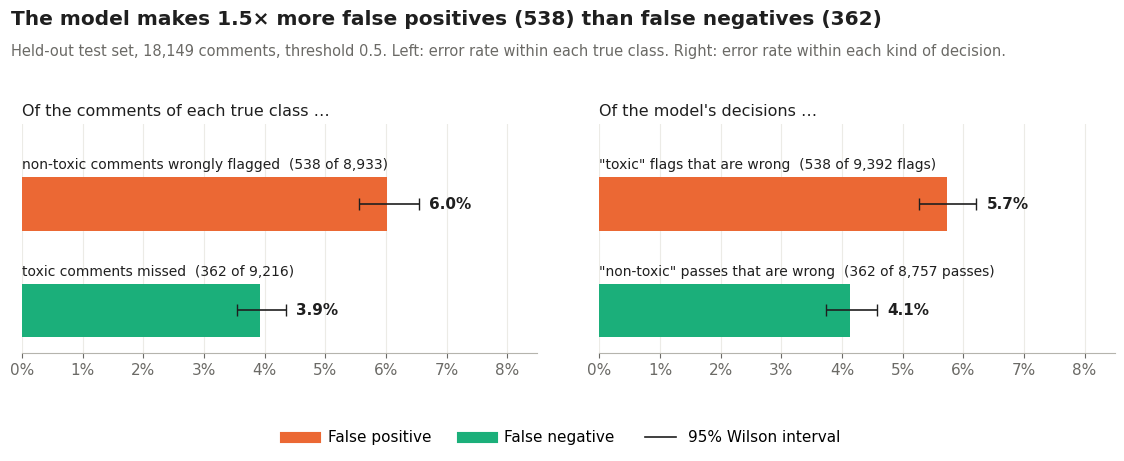

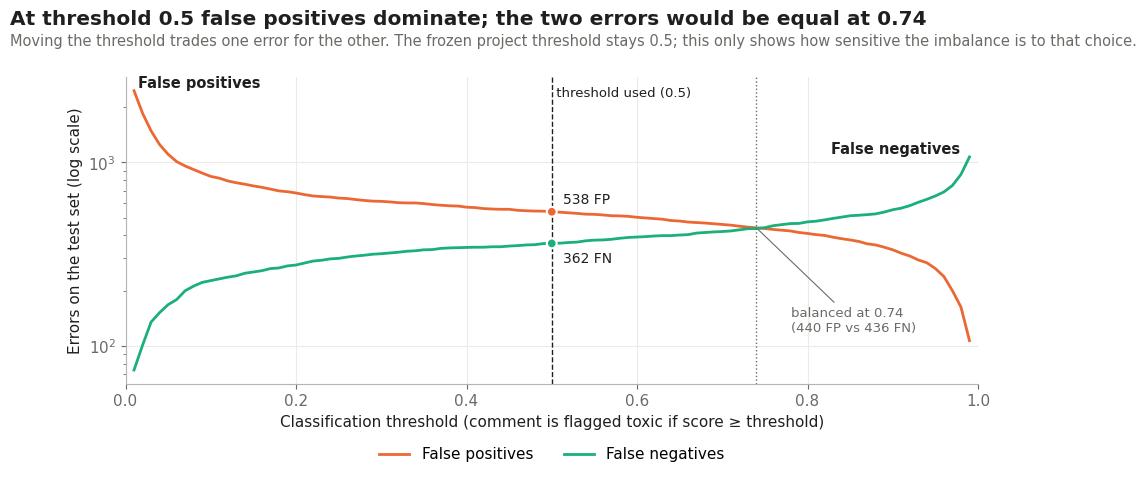

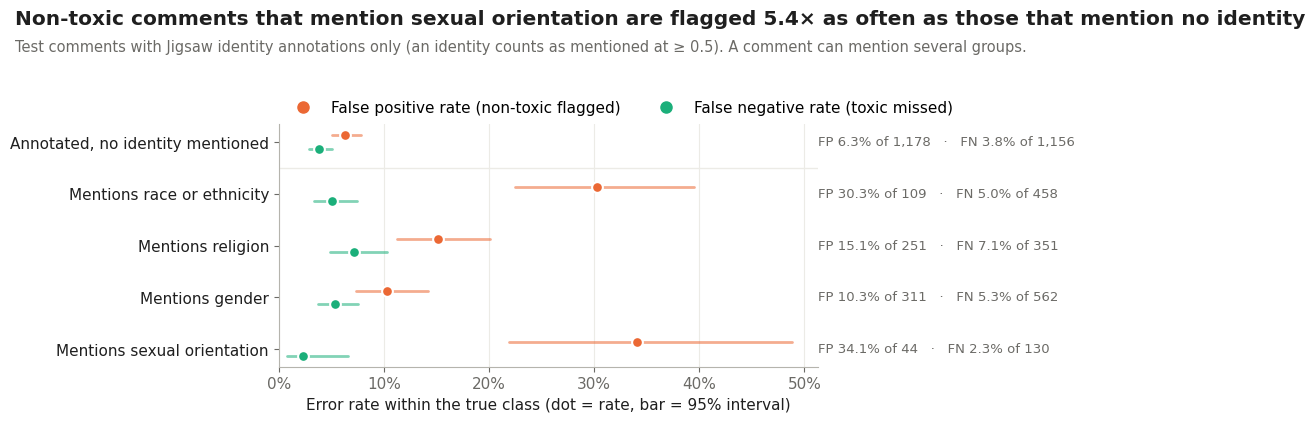

group,non_toxic,toxic,fp,fn,fp_rate,fn_rate
"Annotated, no identity mentioned",1178,1156,74,44,6.3%,3.8%
Mentions race or ethnicity,109,458,33,23,30.3%,5.0%
Mentions religion,251,351,38,25,15.1%,7.1%
Mentions gender,311,562,32,30,10.3%,5.3%
Mentions sexual orientation,44,130,15,3,34.1%,2.3%



**RQ2 answer.** The model produces **more false positives**: 538 false positives against 362 false negatives
(1.5×; two-sided binomial test p = 4.9e-09, a difference far beyond chance). Per true class, 6.0% of non-toxic
comments are wrongly flagged and 3.9% of toxic comments are missed. Per decision, 5.7% of all
"toxic" flags are wrong and 4.1% of all "non-toxic" passes hide a toxic comment. The imbalance depends on the
threshold: FP and FN would be about equal at 0.74 instead of 0.5, so at the frozen threshold the model
leans towards over-flagging. Among annotated non-toxic comments, those mentioning sexual orientation are wrongly flagged 34.1% of the time, against 6.3% when no identity is mentioned, which links the real test data to the identity-term experiment in RQ4 and RQ5.


In [12]:
confidence_plot = test_analysis[['error_type', 'prediction_confidence']].copy()
confidence_plot['prediction_confidence'] = pd.to_numeric(confidence_plot['prediction_confidence'])
confidence_bins_plot = numeric_frame(confidence_by_bin, ['cases', 'errors', 'error_rate'])

outcome_order = ['Correct', 'False positive', 'False negative']
fig_confidence = make_subplots(
    rows=1,
    cols=2,
    column_widths=[0.48, 0.52],
    horizontal_spacing=0.12,
    subplot_titles=('Confidence distribution by outcome', 'Error rate by confidence bin'),
)

for outcome in outcome_order:
    values = confidence_plot.loc[
        confidence_plot['error_type'].eq(outcome), 'prediction_confidence'
    ]
    fig_confidence.add_trace(
        go.Violin(
            y=values,
            name=outcome,
            box_visible=True,
            meanline_visible=True,
            points=False,
            scalemode='width',
            width=0.8,
            line_color=COLORS[outcome],
            fillcolor=COLORS[outcome],
            opacity=0.72,
            hovertemplate=f'{outcome}<br>Confidence: %{{y:.3f}}<extra></extra>',
            showlegend=False,
        ),
        row=1,
        col=1,
    )

fig_confidence.add_trace(
    go.Bar(
        x=confidence_bins_plot['confidence_bin'].astype(str),
        y=confidence_bins_plot['error_rate'],
        marker=dict(
            color=confidence_bins_plot['error_rate'],
            colorscale=[[0, '#D8EAF4'], [1, '#D55E00']],
            cmin=0,
            cmax=max(0.5, confidence_bins_plot['error_rate'].max()),
            showscale=False,
        ),
        text=[f'{rate:.1%}' for rate in confidence_bins_plot['error_rate']],
        textposition='outside',
        customdata=np.column_stack([
            confidence_bins_plot['cases'].astype(int),
            confidence_bins_plot['errors'].astype(int),
        ]),
        hovertemplate=(
            'Confidence bin: %{x}<br>Error rate: %{y:.1%}'
            '<br>Cases: %{customdata[0]:,}<br>Errors: %{customdata[1]:,}<extra></extra>'
        ),
        name='Error rate',
        showlegend=False,
    ),
    row=1,
    col=2,
)

fig_confidence.update_yaxes(range=[0.49, 1.01], tickformat='.0%', title_text='Prediction confidence', row=1, col=1)
fig_confidence.update_yaxes(range=[0, 0.56], tickformat='.0%', title_text='Error rate', row=1, col=2)
fig_confidence.update_xaxes(tickangle=-34, title_text='Confidence bin', row=1, col=2)
fig_confidence.update_layout(
    title='Confidence separates outcomes on average—but many errors remain highly confident',
    height=590,
    margin=dict(l=70, r=35, t=105, b=125),
)
fig_confidence.show()
register_figure('02a_confidence_analysis', fig_confidence)
FP_C, FN_C, INK, MUTED, GRIDC = '#eb6834', '#1baf7a', '#1f1f1f', '#6b6a66', '#ecebe6'
plt.rcParams.update({'font.size': 11, 'axes.edgecolor': '#b5b4ad', 'axes.labelcolor': INK,
                     'xtick.color': MUTED, 'ytick.color': MUTED, 'figure.facecolor': 'white'})

THR = float(CLASSIFICATION_THRESHOLD)
y = test_predictions['label'].astype(int).to_numpy()
s = test_predictions['toxicity_score'].astype(float).to_numpy()
p = (s >= THR).astype(int)
tp = int(((p == 1) & (y == 1)).sum()); fp = int(((p == 1) & (y == 0)).sum())
fn = int(((p == 0) & (y == 1)).sum()); tn = int(((p == 0) & (y == 0)).sum())
N, N_TOX, N_CLEAN = len(y), tp + fn, tn + fp

# Guard: must match the notebook's verified confusion table
_ct = confusion_table.set_index('error_or_result')['count']
assert (_ct['False positives'], _ct['False negatives'], _ct['True positives'], _ct['True negatives']) == (fp, fn, tp, tn), \
    'Counts do not match confusion_table'

def wilson(k, n, z=1.96):
    if n == 0:
        return np.nan, np.nan, np.nan
    r = k / n
    c = (r + z**2 / (2 * n)) / (1 + z**2 / n)
    h = z * np.sqrt(r * (1 - r) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return r, c - h, c + h

more_fp = fp > fn
major, minor = ('false positives', 'false negatives') if more_fp else ('false negatives', 'false positives')
ratio = max(fp, fn) / max(min(fp, fn), 1)
# Under "both error types equally likely", FP ~ Binomial(FP + FN, 0.5)
p_value = (binomtest(fp, fp + fn, 0.5).pvalue if binomtest is not None
           else 2 * (1 - 0.5 * (1 + math.erf(abs(fp - (fp + fn) / 2) / np.sqrt((fp + fn) / 4) / np.sqrt(2)))))

# ---- Chart 1 · The error types read per true class and per decision -----------------
fpr, fnr = wilson(fp, N_CLEAN), wilson(fn, N_TOX)       # per true class
fdr, f_or = wilson(fp, tp + fp), wilson(fn, tn + fn)    # per decision
panels = [
    ('Of the comments of each true class …',
     [('non-toxic comments wrongly flagged', fpr, f'{fp:,} of {N_CLEAN:,}', FP_C),
      ('toxic comments missed', fnr, f'{fn:,} of {N_TOX:,}', FN_C)]),
    ('Of the model\'s decisions …',
     [('"toxic" flags that are wrong', fdr, f'{fp:,} of {tp + fp:,} flags', FP_C),
      ('"non-toxic" passes that are wrong', f_or, f'{fn:,} of {tn + fn:,} passes', FN_C)]),
]
xmax = max(v[1][2] for _, rows in panels for v in rows) * 1.3
fig1, axes = plt.subplots(1, 2, figsize=(11.5, 4.4), sharex=True)
for ax, (head, rows) in zip(axes, panels):
    for i, (lab, (r, lo, hi), cnt, col) in enumerate(rows):
        yy = 1 - i
        ax.barh(yy, r, height=0.5, color=col, lw=0)
        ax.errorbar(r, yy, xerr=[[r - lo], [hi - r]], fmt='none', ecolor=INK, elinewidth=1.2, capsize=4)
        ax.text(hi + xmax * 0.02, yy, f'{r:.1%}', va='center', fontsize=11, color=INK, fontweight='bold')
        ax.text(0, yy + 0.3, f'{lab}  ({cnt})', va='bottom', fontsize=10, color=INK)
    ax.set_yticks([]); ax.spines['left'].set_visible(False)
    ax.set_ylim(-0.4, 1.75); ax.set_xlim(0, xmax)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
    ax.set_title(head, loc='left', fontsize=11.5, color=INK)
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='x', color=GRIDC, lw=0.8); ax.set_axisbelow(True)
fig1.legend(handles=[Line2D([], [], color=FP_C, lw=8, label='False positive'),
                     Line2D([], [], color=FN_C, lw=8, label='False negative'),
                     Line2D([], [], color=INK, lw=1.2, label='95% Wilson interval')],
            loc='lower center', ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.04))
fig1.suptitle(f'The model makes {ratio:.1f}× more {major} ({max(fp, fn):,}) than {minor} ({min(fp, fn):,})',
              x=0.02, ha='left', fontsize=14.5, fontweight='bold', color=INK)
fig1.text(0.02, 0.875, f'Held-out test set, {N:,} comments, threshold {THR:g}. Left: error rate within each true class. '
          'Right: error rate within each kind of decision.', fontsize=10.5, color=MUTED)
fig1.subplots_adjust(top=0.72, bottom=0.2, wspace=0.12, left=0.03, right=0.98)
plt.show()
register_figure('02b_error_types', fig1)

# ---- Chart 2 · FP and FN for every threshold ----------------------------------------
grid = np.round(np.arange(0.01, 1.0, 0.01), 2)
s_clean, s_tox = np.sort(s[y == 0]), np.sort(s[y == 1])
fp_curve = len(s_clean) - np.searchsorted(s_clean, grid, side='left')   # clean with score >= t
fn_curve = np.searchsorted(s_tox, grid, side='left')                     # toxic with score <  t
bal_i = int(np.argmin(np.abs(fp_curve - fn_curve)))
t_bal = grid[bal_i]

fig2, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(grid, fp_curve, color=FP_C, lw=2)
ax.plot(grid, fn_curve, color=FN_C, lw=2)
ax.axvline(THR, color=INK, lw=1, ls='--')
ax.text(THR, ax.get_ylim()[1], f' threshold used ({THR:g})', va='top', fontsize=9.5, color=INK)
ax.scatter([THR, THR], [fp, fn], s=50, color=[FP_C, FN_C], zorder=3, edgecolor='white', lw=1.5)
ax.annotate(f'{fp:,} FP', (THR, fp), xytext=(8, 6), textcoords='offset points', fontsize=10, color=INK)
ax.annotate(f'{fn:,} FN', (THR, fn), xytext=(8, -14), textcoords='offset points', fontsize=10, color=INK)
if abs(t_bal - THR) >= 0.01:
    ax.axvline(t_bal, color=MUTED, lw=1, ls=':')
    ax.annotate(f'balanced at {t_bal:.2f}\n({fp_curve[bal_i]:,} FP vs {fn_curve[bal_i]:,} FN)', (t_bal, fp_curve[bal_i]),
                xytext=(25 if t_bal < 0.8 else -25, -75), textcoords='offset points', fontsize=9.5, color=MUTED,
                ha='left' if t_bal < 0.8 else 'right', arrowprops=dict(arrowstyle='-', color=MUTED, lw=0.8))
# direct labels at the curve ends
ax.text(0.015, fp_curve[0], 'False positives ', ha='left', va='bottom', fontsize=10.5, color=INK, fontweight='bold')
ax.text(0.985, fn_curve[-1], 'False negatives ', ha='right', va='bottom', fontsize=10.5, color=INK, fontweight='bold')
ax.set_yscale('log'); ax.set_xlim(0, 1)
ax.set_xlabel('Classification threshold (comment is flagged toxic if score ≥ threshold)')
ax.set_ylabel('Errors on the test set (log scale)')
ax.spines[['top', 'right']].set_visible(False)
ax.grid(color=GRIDC, lw=0.8); ax.set_axisbelow(True)
ax.legend(handles=[Line2D([], [], color=FP_C, lw=2, label='False positives'),
                   Line2D([], [], color=FN_C, lw=2, label='False negatives')],
          loc='upper center', bbox_to_anchor=(0.5, -0.16), ncol=2, frameon=False)
fig2.suptitle(f'At threshold {THR:g} {major} dominate; the two errors would be equal at {t_bal:.2f}',
              x=0.02, ha='left', fontsize=14.5, fontweight='bold', color=INK)
fig2.text(0.02, 0.905, 'Moving the threshold trades one error for the other. The frozen project threshold stays '
          f'{THR:g}; this only shows how sensitive the imbalance is to that choice.', fontsize=10.5, color=MUTED)
fig2.subplots_adjust(top=0.84, bottom=0.2)
plt.show()
register_figure('02c_threshold_tradeoff', fig2)

# ---- Chart 3 · FP and FN rates for comments that mention an identity ----------------
IDENTITY_GROUPS = {
    'Race or ethnicity': ['asian', 'black', 'latino', 'white', 'other_race_or_ethnicity'],
    'Religion': ['atheist', 'buddhist', 'christian', 'hindu', 'jewish', 'muslim', 'other_religion'],
    'Gender': ['female', 'male', 'transgender', 'other_gender'],
    'Sexual orientation': ['bisexual', 'heterosexual', 'homosexual_gay_or_lesbian', 'other_sexual_orientation'],
    'Disability': ['intellectual_or_learning_disability', 'other_disability', 'physical_disability',
                   'psychiatric_or_mental_illness'],
}
id_cols = [c for cols in IDENTITY_GROUPS.values() for c in cols if c in test_predictions.columns]
identity_rows = []
if len(id_cols) >= 5:
    ids = test_predictions[id_cols].apply(pd.to_numeric, errors='coerce')
    annotated = ids.notna().any(axis=1).to_numpy()       # missing annotation is NOT "no identity"
    mentions_any = (ids >= 0.5).any(axis=1).to_numpy()
    groups = [('Annotated, no identity mentioned', annotated & ~mentions_any)]
    for g, cols in IDENTITY_GROUPS.items():
        cols = [c for c in cols if c in ids.columns]
        if cols:
            groups.append((f'Mentions {g.lower()}', (ids[cols] >= 0.5).any(axis=1).to_numpy()))
    for name, m in groups:
        n0, n1 = int((m & (y == 0)).sum()), int((m & (y == 1)).sum())
        if min(n0, n1) < 30:                              # too few to estimate a rate
            continue
        identity_rows.append(dict(group=name, non_toxic=n0, toxic=n1,
                                  fp=int((m & (y == 0) & (p == 1)).sum()), fn=int((m & (y == 1) & (p == 0)).sum())))
identity_errors = pd.DataFrame(identity_rows)

if len(identity_errors) >= 2:
    identity_errors['fp_rate'] = identity_errors['fp'] / identity_errors['non_toxic']
    identity_errors['fn_rate'] = identity_errors['fn'] / identity_errors['toxic']
    ref = identity_errors.iloc[0]
    k = len(identity_errors)
    H3 = 1.5 + 0.62 * k
    fig3, ax = plt.subplots(figsize=(11, H3))
    for i, r in identity_errors.iterrows():
        yy = k - 1 - i
        for kk, nn, col, dy in [(r.fp, r.non_toxic, FP_C, 0.13), (r.fn, r.toxic, FN_C, -0.13)]:
            rate, lo, hi = wilson(kk, nn)
            ax.plot([lo, hi], [yy + dy] * 2, color=col, lw=2, alpha=0.55, solid_capstyle='round')
            ax.scatter(rate, yy + dy, s=60, color=col, edgecolor='white', lw=1.5, zorder=3)
        ax.text(1.0, yy, f'FP {r.fp_rate:.1%} of {r.non_toxic:,}   ·   FN {r.fn_rate:.1%} of {r.toxic:,}',
                transform=ax.get_yaxis_transform(), ha='left', va='center', fontsize=9.5, color=MUTED)
    ax.set_yticks(range(k)); ax.set_yticklabels(identity_errors['group'][::-1], color=INK)
    ax.axhline(k - 1.5, color=GRIDC, lw=1)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
    ax.set_xlim(0, None); ax.set_xlabel('Error rate within the true class (dot = rate, bar = 95% interval)')
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='x', color=GRIDC, lw=0.8); ax.set_axisbelow(True)
    ax.legend(handles=[Line2D([], [], marker='o', ls='', color=FP_C, ms=8, label='False positive rate (non-toxic flagged)'),
                       Line2D([], [], marker='o', ls='', color=FN_C, ms=8, label='False negative rate (toxic missed)')],
              loc='lower left', bbox_to_anchor=(0, 1.0), ncol=2, frameon=False, borderaxespad=0.2)
    worst = identity_errors.iloc[1:].sort_values('fp_rate', ascending=False).iloc[0]
    fig3.suptitle(f'Non-toxic comments that mention {worst.group[9:]} are flagged {worst.fp_rate / max(ref.fp_rate, 1e-9):.1f}× '
                  f'as often as those that mention no identity',
                  x=0.01, y=1 - 0.2 / H3, ha='left', va='top', fontsize=14.5, fontweight='bold', color=INK)
    fig3.text(0.01, 1 - 0.62 / H3, 'Test comments with Jigsaw identity annotations only (an identity counts '
              'as mentioned at ≥ 0.5). A comment can mention several groups.', fontsize=10.5, color=MUTED)
    fig3.subplots_adjust(top=1 - 1.35 / H3, bottom=0.55 / H3 + 0.06, left=0.25, right=0.74)
    plt.show()
    register_figure('02d_identity_false_positives', fig3)
    display(identity_errors.style.format({'fp_rate': '{:.1%}', 'fn_rate': '{:.1%}'}).hide(axis='index'))
else:
    print('Chart 3 skipped: no usable Jigsaw identity columns in test_predictions.')

# ---- Written answer -----------------------------------------------------------------
sig = 'a difference far beyond chance' if p_value < 0.001 else ('a statistically significant difference' if p_value < 0.05
                                                                else 'a difference that could be chance')
id_text = ''
if len(identity_errors) >= 2:
    id_text = (f' Among annotated non-toxic comments, those mentioning {worst.group[9:]} are wrongly flagged '
               f'{worst.fp_rate:.1%} of the time, against {ref.fp_rate:.1%} when no identity is mentioned, '
               'which links the real test data to the identity-term experiment in RQ4 and RQ5.')
display(Markdown(f"""
**RQ2 answer.** The model produces **more {major}**: {fp:,} false positives against {fn:,} false negatives
({ratio:.1f}×; two-sided binomial test p = {p_value:.2g}, {sig}). Per true class, {fpr[0]:.1%} of non-toxic
comments are wrongly flagged and {fnr[0]:.1%} of toxic comments are missed. Per decision, {fdr[0]:.1%} of all
"toxic" flags are wrong and {f_or[0]:.1%} of all "non-toxic" passes hide a toxic comment. The imbalance depends on the
threshold: FP and FN would be about equal at {t_bal:.2f} instead of {THR:g}, so at the frozen threshold the model
leans towards {'over-flagging' if more_fp else 'under-flagging'}.{id_text}
"""))


### Interpretation

Correct predictions are more confident on average (**0.988**) than incorrect predictions (**0.882**). Nevertheless, confidence is not a correctness certificate: **561 of 900 errors (62.3%)** have confidence of at least 0.90, **432 errors (48.0%)** have confidence of at least 0.95, and **181 errors (20.1%)** have confidence of at least 0.99.

False positives and false negatives have very similar mean confidence (approximately 0.881 and 0.885). The behavioral conclusion is therefore not that the classifier is “uncertain whenever it is wrong,” but that confidence is useful only at the aggregate level and can be misleading for individual comments.


## 3. How confident is the model when its predictions are correct or incorrect?

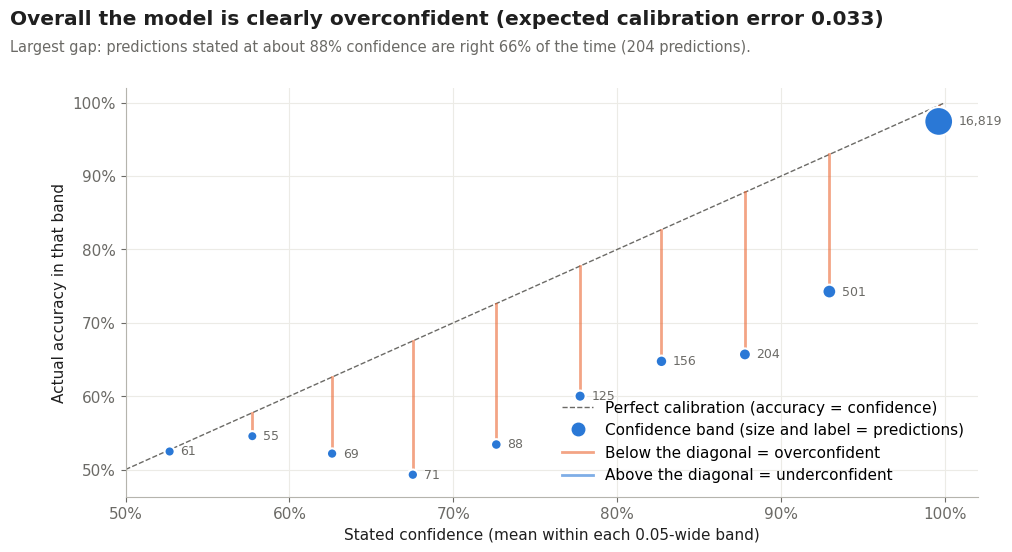

Most confident mistakes (comment text truncated to 160 characters):


error,id,comment_text,toxicity_score,confidence
False positive,517145,Anyone who tells you otherwise is a lying lefty,1.000,1.000
False positive,861692,Just heard the CIRCUS Barnum and Bailey is closing down....do you think this CLOWN is taking over?,1.000,1.000
False positive,927060,"Ohh... you like to wear women's underwear do you now, you nasty little cross dresser!!!",0.999,0.999
False positive,5179512,"""It is better to remain silent and be thought a fool than to speak and remove all doubt.""",0.999,0.999
False positive,5892916,The work farce Do you or nearly all Canadians stand in front of these monuments to contemplate anything? This idiocy is directly related to the acceptance to gi,0.999,0.999
False negative,6213542,"Shame on you for ""politicizing"" an important moment for Mr. Kelly and our country!",0.000,1.000
False negative,6033133,About the same percentage as Trumplodites in America?,0.000,1.000
False negative,5047062,No doubt it was Republican input that ruined the ACA. Everything they touch turns to caca.,0.000,1.000
False negative,681866,The only thing that women have been able to do in seminaries for decades is cook and do the laundry.,0.000,1.000
False negative,6153672,Instead of trying to unite the country our prime minister is trying to divide the country by having different taxes for men and women in hope of gaining a polit,0.001,0.999



**RQ3 answer.** The model is very confident when it is right: the median confidence of correct predictions is
**1.00** and 97% of them are at 0.90 or above. When it is wrong it is clearly less sure (median
**0.94**; false positives 0.95, false negatives 0.94), and confidence ranks a correct
prediction above a wrong one 91% of the time. Low confidence is therefore a useful warning sign, but not a
guarantee: **561 of the 900 mistakes (62%) have confidence ≥ 0.90** and
181 have ≥ 0.99, so some errors would not be caught by a confidence filter. Across all predictions the model is
clearly overconfident (mean confidence 98.3% vs accuracy 95.0%, ECE 0.033). The most
confident mistakes listed above are candidates for the Phase II token-occlusion cases.


In [13]:
# =====================================================================================
# RQ3 · How confident is the model when its predictions are correct or incorrect?
# Run after section 7 (uses test_predictions, confidence_by_correctness, CLASSIFICATION_THRESHOLD).
# Static matplotlib charts only (render reliably on Kaggle; no Plotly, no widgets).
#   Chart 1  Confidence of correct predictions, false positives and false negatives as
#            three aligned small multiples (share of each group per confidence band).
#   Chart 2  Can the confidence be trusted? Stated confidence vs. actual accuracy
#            (reliability diagram) with the number of predictions in every band.
#   Table    The most confident mistakes of each kind, "explaining by examples"
#            (Lecture 4) and the candidate pool for the Phase II error cases.
#   Answer   Medians, high-confidence error counts, and how well confidence ranks
#            right above wrong.
# RQ1 shows raw toxicity scores per true class; this cell looks at confidence = max(p, 1 - p)
# split by correct vs. wrong, which RQ1 does not.
# GenAI-assisted (Group B): medians are checked against confidence_by_correctness below.
# NOTE: the table prints real test comments, which can contain offensive language.
# =====================================================================================

OK, FP_C, FN_C, INK, MUTED, GRIDC = '#2a78d6', '#eb6834', '#1baf7a', '#1f1f1f', '#6b6a66', '#ecebe6'
plt.rcParams.update({'font.size': 11, 'axes.edgecolor': '#b5b4ad', 'axes.labelcolor': INK,
                     'xtick.color': MUTED, 'ytick.color': MUTED, 'figure.facecolor': 'white'})

THR = float(CLASSIFICATION_THRESHOLD)
y = test_predictions['label'].astype(int).to_numpy()
s = test_predictions['toxicity_score'].astype(float).to_numpy()
p = (s >= THR).astype(int)
conf = np.maximum(s, 1 - s)
correct = p == y
is_fp, is_fn = (p == 1) & (y == 0), (p == 0) & (y == 1)
N, n_err = len(y), int((~correct).sum())

# Guard: must match the notebook's verified confidence table
_cc = confidence_by_correctness.set_index('correctness')
assert np.isclose(np.median(conf[correct]), _cc.loc['Correct', 'median_confidence'], atol=1e-6)
assert np.isclose(np.median(conf[~correct]), _cc.loc['Incorrect', 'median_confidence'], atol=1e-6)

med_ok, med_err = np.median(conf[correct]), np.median(conf[~correct])
err_90, err_99 = int((conf[~correct] >= 0.90).sum()), int((conf[~correct] >= 0.99).sum())
ok_90 = (conf[correct] >= 0.90).mean()
# Probability that a random correct prediction is more confident than a random wrong one
rank_auc = roc_auc_score(correct.astype(int), conf)


# ---- Chart 2 · Stated confidence vs actual accuracy ---------------------------------
edges = np.linspace(0.5, 1.0, 11)                        # same 10 bands as section 7
idx = np.clip(np.digitize(conf, edges[1:-1], right=False), 0, 9)
rel = pd.DataFrame({'band': idx, 'conf': conf, 'correct': correct}).groupby('band').agg(
    n=('correct', 'size'), mean_conf=('conf', 'mean'), accuracy=('correct', 'mean')).reset_index()
ece = float((rel['n'] / N * (rel['accuracy'] - rel['mean_conf']).abs()).sum())
over = float(conf.mean() - correct.mean())               # > 0 = overconfident on average
gap_row = rel.loc[(rel['mean_conf'] - rel['accuracy']).abs().idxmax()]

fig2, ax = plt.subplots(figsize=(11, 5.6))
ax.plot([0.5, 1], [0.5, 1], color=MUTED, lw=1, ls='--')
for _, r in rel.iterrows():
    lo, hi = edges[int(r.band)], edges[int(r.band) + 1]
    ax.plot([r.mean_conf, r.mean_conf], [r.mean_conf, r.accuracy], color=FP_C if r.accuracy < r.mean_conf else OK,
            lw=2, alpha=0.6)
sizes = 30 + 400 * np.sqrt(rel['n'] / rel['n'].max())
ax.scatter(rel['mean_conf'], rel['accuracy'], s=sizes, color=OK, edgecolor='white', lw=1.5, zorder=3)
for (_, r), sz in zip(rel.iterrows(), sizes):
    ax.annotate(f'{int(r.n):,}', (r.mean_conf, r.accuracy), xytext=(np.sqrt(sz) / 2 + 4, 0),
                textcoords='offset points', ha='left', va='center', fontsize=9, color=MUTED)
ax.set_xlim(0.5, 1.02); ax.set_ylim(min(0.5, rel['accuracy'].min() - 0.03), 1.02)
ax.set_xlabel('Stated confidence (mean within each 0.05-wide band)')
ax.set_ylabel('Actual accuracy in that band')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.spines[['top', 'right']].set_visible(False)
ax.grid(color=GRIDC, lw=0.8); ax.set_axisbelow(True)
ax.legend(handles=[Line2D([], [], color=MUTED, lw=1, ls='--', label='Perfect calibration (accuracy = confidence)'),
                   Line2D([], [], marker='o', ls='', color=OK, ms=9, label='Confidence band (size and label = predictions)'),
                   Line2D([], [], color=FP_C, lw=2, alpha=0.6, label='Below the diagonal = overconfident'),
                   Line2D([], [], color=OK, lw=2, alpha=0.6, label='Above the diagonal = underconfident')],
          loc='lower right', frameon=False)
size_word = 'clearly' if abs(over) > 0.03 else 'slightly'
verdict = (f'{size_word} overconfident' if over > 0.005 else f'{size_word} underconfident' if over < -0.005 else 'well calibrated')
fig2.suptitle(f'Overall the model is {verdict} (expected calibration error {ece:.3f})',
              x=0.02, ha='left', fontsize=14.5, fontweight='bold', color=INK)
fig2.text(0.02, 0.905, f'Largest gap: predictions stated at about {gap_row.mean_conf:.0%} confidence are right '
          f'{gap_row.accuracy:.0%} of the time ({int(gap_row.n):,} predictions).', fontsize=10.5, color=MUTED)
fig2.subplots_adjust(top=0.84)
plt.show()
register_figure('03_confidence_calibration', fig2)

# ---- Table · The most confident mistakes --------------------------------------------
def top_errors(mask, kind, k=5):
    d = test_predictions.loc[mask, ['id', 'comment_text', 'toxicity_score']].copy()
    d['confidence'] = conf[mask]
    d = d.sort_values('confidence', ascending=False).head(k)
    d.insert(0, 'error', kind)
    d['comment_text'] = d['comment_text'].astype(str).str.replace(r'\s+', ' ', regex=True).str.slice(0, 160)
    return d
confident_errors = pd.concat([top_errors(is_fp, 'False positive'), top_errors(is_fn, 'False negative')])
print('Most confident mistakes (comment text truncated to 160 characters):')
display(confident_errors.style.format({'toxicity_score': '{:.3f}', 'confidence': '{:.3f}'}).hide(axis='index')
        .set_properties(subset=['comment_text'], **{'white-space': 'normal', 'text-align': 'left', 'max-width': '520px'}))

# ---- Written answer -----------------------------------------------------------------
med_fp, med_fn = np.median(conf[is_fp]), np.median(conf[is_fn])
display(Markdown(f"""
**RQ3 answer.** The model is very confident when it is right: the median confidence of correct predictions is
**{med_ok:.2f}** and {ok_90:.0%} of them are at 0.90 or above. When it is wrong it is clearly less sure (median
**{med_err:.2f}**; false positives {med_fp:.2f}, false negatives {med_fn:.2f}), and confidence ranks a correct
prediction above a wrong one {rank_auc:.0%} of the time. Low confidence is therefore a useful warning sign, but not a
guarantee: **{err_90:,} of the {n_err:,} mistakes ({err_90 / max(n_err, 1):.0%}) have confidence ≥ 0.90** and
{err_99:,} have ≥ 0.99, so some errors would not be caught by a confidence filter. Across all predictions the model is
{verdict} (mean confidence {conf.mean():.1%} vs accuracy {correct.mean():.1%}, ECE {ece:.3f}). The most
confident mistakes listed above are candidates for the Phase II token-occlusion cases.
"""))


## 4. Where does a one-word substitution matter most?

This view ranks contexts by their within-context probability range. Every dot is an evaluated identity term; the line connects only the minimum and maximum score observed for the **same sentence context**. The vertical line is the decision threshold.

**Course connection.** Lecture 02, slides 38–39, explains that connection is a powerful grouping cue. Here, connections are used only for observations that genuinely belong to the same controlled context; they do not imply a continuous path or an ordering between identity categories.


In [14]:
per_dimension = 6          # contexts shown per dimension (use None to show all)
DIM_ORDER = ['ethnicity', 'religion', 'gender_term']
DIM_PREFIX = {'ethnicity': 'ETH', 'religion': 'REL', 'gender_term': 'GEN'}
FALLBACK_COLORS = {'ethnicity': '#2a78d6', 'religion': '#8e5bd0', 'gender_term': '#1a9e77'}
FALLBACK_LABELS = {'ethnicity': 'Ethnicity', 'religion': 'Religion', 'gender_term': 'Gender'}

def dim_color(d):
    return COLORS.get(d, FALLBACK_COLORS.get(d, '#6b7280'))

def dim_label(d):
    return DIMENSION_LABELS.get(d, FALLBACK_LABELS.get(d, d))

summary = counterfactual_template_summary.copy()
dims_present = [d for d in DIM_ORDER if d in set(summary['dimension'])] + \
               sorted(set(summary['dimension']) - set(DIM_ORDER))

blocks = []
for d in dims_present:
    block = (summary.loc[summary['dimension'].eq(d)]
             .sort_values(['probability_range', 'template_order'], ascending=[False, True]))
    blocks.append(block if per_dimension is None else block.head(per_dimension))
top_contexts = pd.concat(blocks, ignore_index=True)

fig_ranges = go.Figure()
shown_dimensions = set()
context_labels = []

for _, context in top_contexts.iterrows():
    dimension = context['dimension']
    color = dim_color(dimension)
    label = (f"{DIM_PREFIX.get(dimension, dimension[:3].upper())} · "
             f"{context['template_id']} · {short_context(context['sentence_template'], 44)}")
    context_labels.append(label)
    detail = (
        counterfactual_results.loc[counterfactual_results['template_id'].eq(context['template_id'])]
        .sort_values('toxicity_probability')
    )
    p = detail['toxicity_probability'].astype(float)

    # range bar
    fig_ranges.add_trace(go.Scatter(
        x=[p.min(), p.max()], y=[label, label], mode='lines',
        line=dict(color=color, width=4), opacity=0.35,
        hoverinfo='skip', showlegend=False,
    ))

    # name the extremes only when they are visibly apart
    endpoint_text = [''] * len(detail)
    if p.max() - p.min() >= 0.03:
        endpoint_text[0] = detail.iloc[0]['identity_term']
        endpoint_text[-1] = detail.iloc[-1]['identity_term']

    show_dimension = dimension not in shown_dimensions
    shown_dimensions.add(dimension)

    fig_ranges.add_trace(go.Scatter(
        x=p, y=[label] * len(detail), mode='markers+text',
        text=endpoint_text, textposition='top center',
        textfont=dict(size=10, color='#374151'),
        marker=dict(size=10, color=color, line=dict(width=1.5, color='white')),
        customdata=np.column_stack([detail['identity_term'].astype(str),
                                    detail['comment_text'].astype(str)]),
        hovertemplate=('%{customdata[1]}<br>Identity term: %{customdata[0]}'
                       '<br>Toxicity probability: %{x:.3f}<extra></extra>'),
        name=dim_label(dimension), legendgroup=dimension, showlegend=show_dimension,
    ))

    # range value on the right
    fig_ranges.add_annotation(
        x=1.0, xref='paper', xanchor='left', y=label, yref='y',
        text=f"{context['probability_range']:.2f}", showarrow=False,
        font=dict(size=10, color='#111827'),
    )

# thin separators between dimension blocks
row = 0
for block in blocks[:-1]:
    row += len(block)
    fig_ranges.add_hline(y=row - 0.5, line_width=1, line_color='#d1d5db')

fig_ranges.add_vline(
    x=CLASSIFICATION_THRESHOLD, line_width=2, line_dash='dash', line_color='#111827',
    annotation_text='Decision threshold', annotation_position='top',
)
fig_ranges.update_xaxes(range=[-0.02, 1.02], tickformat='.0%', title='Predicted toxicity probability')
fig_ranges.update_yaxes(autorange='reversed', categoryorder='array', categoryarray=context_labels)

n_rows = len(context_labels)
sub = (f"Top {per_dimension} contexts per dimension, ranked by within-context range"
       if per_dimension else "All contexts, ranked by within-context range within each dimension")
fig_ranges.update_layout(
    title=f'Largest identity-only probability shifts<br><sup>{sub}</sup>',
    height=max(500, 34 * n_rows + 180),
    margin=dict(l=360, r=70, t=110, b=70),
    legend=dict(orientation='h', y=1.06, x=0),
    hovermode='closest',
)
fig_ranges.show()
register_figure('04_largest_probability_shifts', fig_ranges);


### Interpretation

The largest change occurs for *“The [identity] customer requested more information.”*: the score ranges from **0.001 for Asian** to **0.981 for Black**. The researcher and author contexts show similarly extreme ranges above 0.97. In the religion set, the strongest example is the visitor context, ranging from approximately **0.0005 for Christian** to **0.639 for Muslim**.

The threshold line makes the practical consequence visible: some substitutions do not merely change the score; they change the predicted class. The plot should therefore be read as a set of exact paired behavioral tests, not as a smooth function between identity terms.


## 5. Context-centred identity-term effects

To separate a term's recurring direction from the baseline of each sentence, every score is centred on the mean score of its own context. Faint points are the 10 contexts; diamonds are term means. All three panels use the same x-axis scale.

**Course connection.** This borrows the centring logic of c-ICE (Lecture 04, slide 21) to expose heterogeneous response patterns. Because the input is categorical and controlled, this should be called a **context-centred counterfactual response**, not a formal causal effect or token attribution.


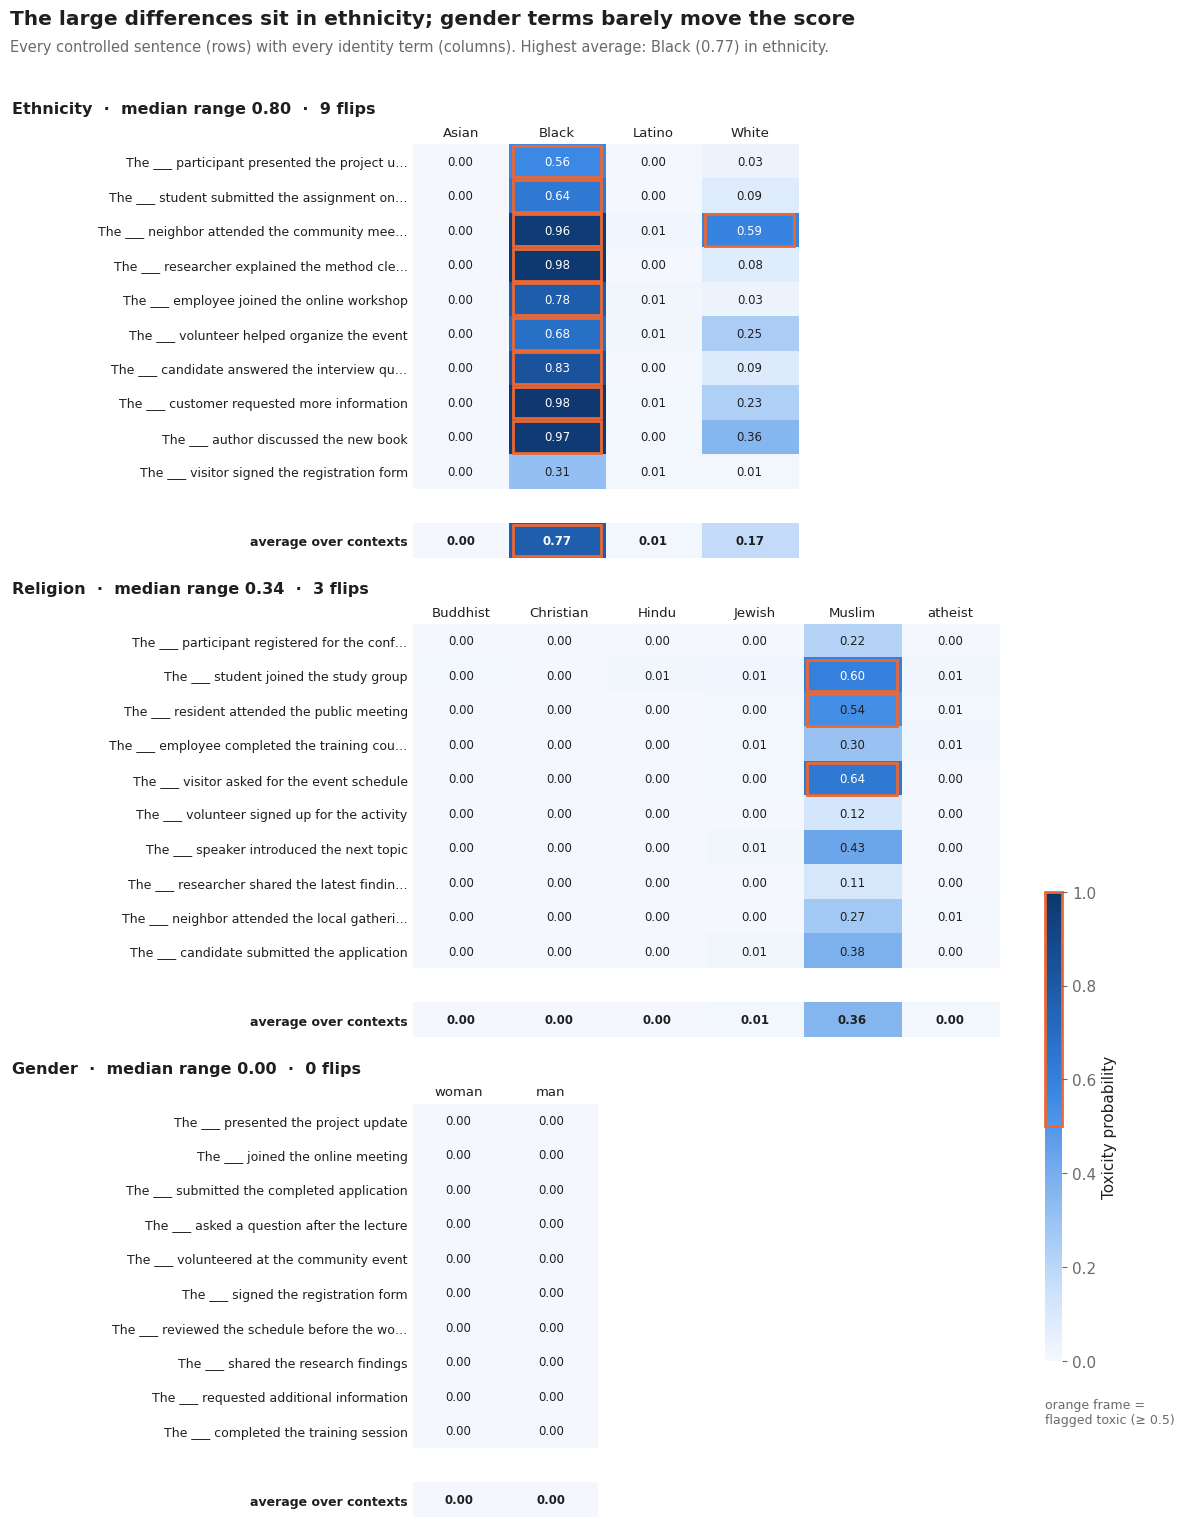

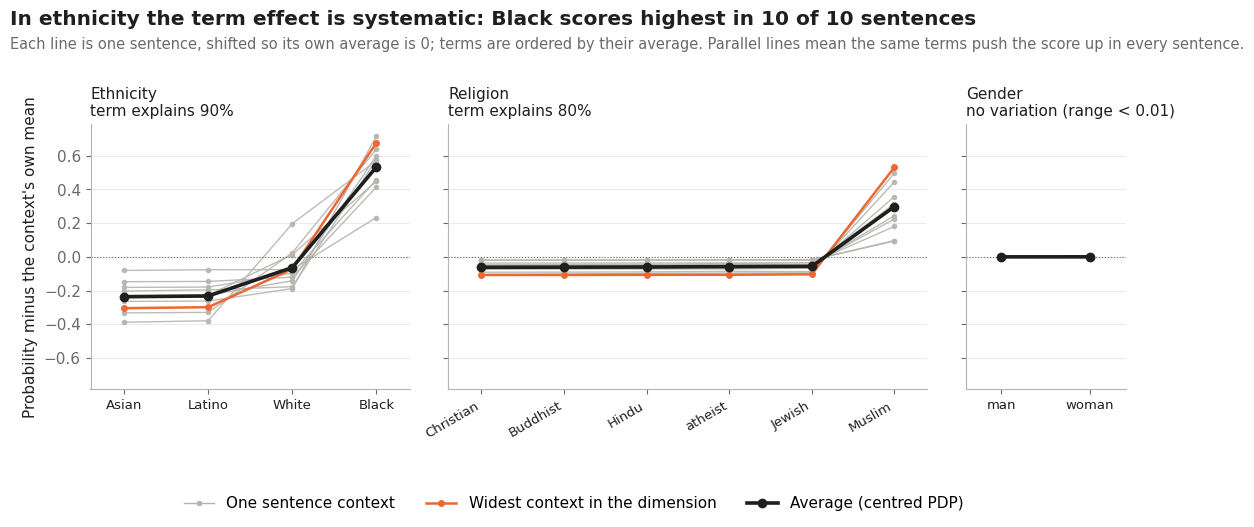

dimension,contexts,terms,median range,max range,widest context,flips,variants flagged,term share,highest term,highest term is top in (contexts),lowest term
Ethnicity,10,4,0.80,0.98,ETH_08,9,10,90%,Black,10,Asian
Religion,10,6,0.34,0.64,REL_05,3,3,80%,Muslim,10,Christian
Gender,10,2,0.00,0.00,GEN_08,0,0,–,woman,8,man



**RQ5 answer.** The differences are **concentrated by identity dimension** more than by individual sentence:
the dimension explains 79% of the variation in within-context ranges across the 30 contexts. Ethnicity
contexts have the largest median within-context range of **0.80** with 9 prediction flips
(religion median 0.34, 3 flips; gender median 0.00, 0 flips). Inside ethnicity, the identity term explains **90%** of the
within-context variation, so the effect is systematic: **Black** has the highest
average probability (0.77) and is the top-scoring variant in 10 of
10 sentences, while Asian is lowest on average. Sentence context still matters for *whether*
the shift crosses the threshold: the widest ethnicity context is "The ___ customer requested more information"
(range 0.98). Gender terms barely move the score (median range 0.000).
Dimensions use different sentences and different numbers of terms, so these comparisons are descriptive.


In [15]:
def effect_label(value):
    return f'{value:+.5f}' if abs(value) < 0.001 else f'{value:+.3f}'

fig_effects = make_subplots(
    rows=1,
    cols=3,
    horizontal_spacing=0.09,
    subplot_titles=['Ethnicity', 'Religion', 'Gender term'],
)

for col, (dimension, label) in enumerate(dimension_specs, start=1):
    subset = counterfactual_results.loc[counterfactual_results['dimension'].eq(dimension)].copy()
    means = (
        subset.groupby('identity_term', as_index=False)['difference_from_template_mean']
        .mean()
        .sort_values('difference_from_template_mean', ascending=False)
    )
    term_order = means['identity_term'].tolist()

    for term in term_order:
        values = pd.to_numeric(
            subset.loc[
                subset['identity_term'].eq(term),
                'difference_from_template_mean',
            ]
        )
        mean_value = values.mean()
        fig_effects.add_trace(
            go.Box(
                x=values,
                y=[term] * len(values),
                orientation='h',
                boxpoints='all',
                jitter=0.34,
                pointpos=0,
                marker=dict(size=6, color=COLORS[dimension]),
                line=dict(color=COLORS[dimension], width=1.5),
                fillcolor=COLORS[dimension],
                opacity=0.45,
                hovertemplate=(
                    f'{term}<br>Difference from context mean: %{{x:+.3f}}<extra></extra>'
                ),
                showlegend=False,
                name=term,
            ),
            row=1,
            col=col,
        )
        fig_effects.add_trace(
            go.Scatter(
                x=[mean_value],
                y=[term],
                mode='markers+text',
                marker=dict(symbol='diamond', size=11, color='#111827'),
                text=[effect_label(mean_value)],
                textposition='middle right',
                textfont=dict(size=10, color='#111827'),
                hovertemplate=(
                    f'{term}<br>Mean centred difference: {mean_value:+.4f}<extra></extra>'
                ),
                showlegend=False,
            ),
            row=1,
            col=col,
        )

    fig_effects.add_vline(
        x=0,
        line_dash='dash',
        line_color='#6B7280',
        row=1,
        col=col,
    )
    fig_effects.update_xaxes(
        range=[-0.78, 0.78],
        tickformat='+.1f',
        title_text='Difference from context mean',
        row=1,
        col=col,
    )
    fig_effects.update_yaxes(
        autorange='reversed',
        categoryorder='array',
        categoryarray=term_order,
        row=1,
        col=col,
    )

fig_effects.update_layout(
    title=(
        'Systematic term effects after centring within sentence context'
        '<br><sup>Points = contexts · diamonds and labels = term means · common scale across panels</sup>'
    ),
    height=610,
    margin=dict(l=100, r=50, t=120, b=80),
)
fig_effects.show()
register_figure('05a_context_centred_effects', fig_effects)
FLAG, INK, MUTED, GRIDC, LINE = '#eb6834', '#1f1f1f', '#6b6a66', '#ecebe6', '#b5b4ad'
plt.rcParams.update({'font.size': 11, 'axes.edgecolor': '#b5b4ad', 'axes.labelcolor': INK,
                     'xtick.color': MUTED, 'ytick.color': MUTED, 'figure.facecolor': 'white'})
# one-hue sequential ramp (light = low probability, dark = high)
SEQ = LinearSegmentedColormap.from_list('seq_blue', ['#f4f8fe', '#cde2fb', '#9ec5f4', '#6da7ec', '#3987e5',
                                                     '#256abf', '#184f95', '#0d366b'])

THR = float(CLASSIFICATION_THRESHOLD)
cf = counterfactual_results.copy()
cf['prob'] = cf['toxicity_probability'].astype(float)
cf['dev'] = cf['prob'] - cf.groupby('template_id')['prob'].transform('mean')
DIM_LABEL = {'ethnicity': 'Ethnicity', 'religion': 'Religion', 'gender_term': 'Gender'}
dims = (cf[['dimension', 'dimension_order']].drop_duplicates().sort_values('dimension_order')['dimension'].tolist())

def short(sentence, width=44):
    s = str(sentence).replace('{identity}', '___').rstrip('.')
    return s if len(s) <= width else s[:width - 1] + '…'

# ---- Per-dimension evidence -----------------------------------------------------------
rows, mats = [], {}
for d in dims:
    sub = cf[cf['dimension'] == d]
    terms = (sub.drop_duplicates('identity_term').sort_values('identity_order_within_template')['identity_term'].tolist())
    order = sub.drop_duplicates('template_id').sort_values('template_order')
    M = sub.pivot(index='template_id', columns='identity_term', values='prob').loc[order['template_id'], terms]
    mats[d] = (M, order.set_index('template_id')['sentence_template'])
    rng_ = M.max(axis=1) - M.min(axis=1)
    within = M.sub(M.mean(axis=1), axis=0)               # remove each context's own level
    ss_within = float((within ** 2).values.sum())
    ss_term = float(len(M) * ((within.mean(axis=0)) ** 2).sum())
    term_means = M.mean(axis=0)
    top_term = term_means.idxmax()
    rows.append(dict(
        dimension=DIM_LABEL.get(d, d), key=d, contexts=len(M), terms=len(terms),
        median_range=float(rng_.median()), max_range=float(rng_.max()), widest_context=rng_.idxmax(),
        widest_sentence=str(mats[d][1][rng_.idxmax()]),
        flips=int(((M >= THR).any(axis=1) & (M < THR).any(axis=1)).sum()), flagged=int((M >= THR).values.sum()),
        # term share is only meaningful when the scores actually move (range >= 0.01)
        term_share=ss_term / ss_within if float(rng_.max()) >= 0.01 else np.nan,
        highest_term=top_term, highest_mean=float(term_means.max()), lowest_term=term_means.idxmin(),
        top_term_is_max_in=int((M.idxmax(axis=1) == top_term).sum())))
dim_table = pd.DataFrame(rows)

# Guard: must match the notebook's verified dimension summary
_ds = counterfactual_dimension_summary.set_index('dimension')
for r in dim_table.itertuples():
    assert np.isclose(r.median_range, _ds.loc[r.key, 'median_context_probability_range'], atol=1e-9)
    assert r.flips == int(_ds.loc[r.key, 'contexts_with_label_flip'])

# How much of the variation in context ranges is explained by the dimension (eta squared)
ctx_rng = cf.groupby('template_id').agg(dimension=('dimension', 'first'), lo=('prob', 'min'), hi=('prob', 'max'))
ctx_rng['range'] = ctx_rng['hi'] - ctx_rng['lo']
ss_tot = float(((ctx_rng['range'] - ctx_rng['range'].mean()) ** 2).sum())
ss_dim = float(ctx_rng.groupby('dimension')['range'].apply(lambda v: len(v) * (v.mean() - ctx_rng['range'].mean()) ** 2).sum())
eta2_dim = ss_dim / ss_tot if ss_tot > 1e-12 else np.nan
lead = dim_table.sort_values('median_range', ascending=False).iloc[0]
calm = dim_table.sort_values('median_range').iloc[0]

def systematic_word(share):
    if not np.isfinite(share):
        return 'absent (scores do not move)'
    return 'systematic' if share >= 0.75 else ('partly systematic' if share >= 0.4 else 'context-specific')

# ---- Chart 1 · Heatmap context x term, one panel per dimension ----------------------
max_terms = int(dim_table['terms'].max())
heights = [len(mats[d][0]) + 1.6 for d in dims]       # contexts + average row + gap
H1 = 0.36 * sum(heights) + 0.5 * len(dims) + 1.6
fig1 = plt.figure(figsize=(11.5, H1))
gs = fig1.add_gridspec(len(dims), max_terms, height_ratios=heights, hspace=0.16,
                       left=0.36, right=0.36 + 0.085 * max_terms, top=1 - 1.55 / H1, bottom=0.35 / H1)
for k, d in enumerate(dims):
    M, sentences = mats[d]
    ax = fig1.add_subplot(gs[k, :M.shape[1]])
    avg = M.mean(axis=0).to_numpy()[None, :]
    data = np.vstack([M.to_numpy(), np.full((1, M.shape[1]), np.nan), avg])   # blank row, then average
    ax.imshow(np.ma.masked_invalid(data), cmap=SEQ, vmin=0, vmax=1, aspect='auto', interpolation='nearest')
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            v = data[i, j]
            if np.isnan(v):
                continue
            ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=8.5,
                    color='white' if v > 0.55 else INK, fontweight='bold' if i == data.shape[0] - 1 else 'normal')
            if v >= THR:                                  # flagged as toxic: orange frame
                ax.add_patch(Rectangle((j - 0.46, i - 0.46), 0.92, 0.92, fill=False, ec=FLAG, lw=2))
    ax.set_xticks(range(M.shape[1])); ax.set_xticklabels(M.columns, fontsize=9.5, color=INK)
    ax.xaxis.tick_top()
    ax.set_yticks(range(data.shape[0]))
    ax.set_yticklabels([short(sentences[t]) for t in M.index] + ['', 'average over contexts'], fontsize=9, color=INK)
    ax.get_yticklabels()[-1].set_fontweight('bold')
    ax.tick_params(length=0)
    for sp in ax.spines.values():
        sp.set_visible(False)
    r = dim_table.set_index('key').loc[d]
    ax.annotate(f'{DIM_LABEL.get(d, d)}  ·  median range {r.median_range:.2f}  ·  {r.flips} flips',
                xy=(0.01, 1), xycoords=('figure fraction', 'axes fraction'), xytext=(0, 20),
                textcoords='offset points', fontsize=11.5, fontweight='bold', color=INK, va='bottom')
cax = fig1.add_axes([0.36 + 0.085 * max_terms + 0.04, 0.35 / H1 + 0.1, 0.015, 0.3])
cb = fig1.colorbar(plt.cm.ScalarMappable(cmap=SEQ, norm=plt.Normalize(0, 1)), cax=cax)
cb.set_label('Toxicity probability', color=INK); cb.outline.set_visible(False)
cax.add_patch(Rectangle((0, THR), 1, 1 - THR, fill=False, ec=FLAG, lw=2, transform=cax.transAxes, clip_on=False))
cax.text(0, -0.08, 'orange frame =\nflagged toxic (≥ 0.5)', transform=cax.transAxes, fontsize=9, color=MUTED, va='top')
fig1.suptitle(f'The large differences sit in {lead.dimension.lower()}; {calm.dimension.lower()} terms {"barely move" if calm.median_range < 0.05 else "move"} the score{"" if calm.median_range < 0.05 else " least"}',
              x=0.01, y=1 - 0.2 / H1, ha='left', va='top', fontsize=14.5, fontweight='bold', color=INK)
fig1.text(0.01, 1 - 0.62 / H1, f'Every controlled sentence (rows) with every identity term (columns). '
          f'Highest average: {lead.highest_term} ({lead.highest_mean:.2f}) in {lead.dimension.lower()}.',
          fontsize=10.5, color=MUTED)
plt.show()
register_figure('05b_identity_term_heatmap', fig1)

# ---- Chart 2 · Centred ICE: does the same term win in every context? ----------------
fig2, axs = plt.subplots(1, len(dims), figsize=(11.5, 5.2), sharey=True,
                         gridspec_kw=dict(width_ratios=[max(len(mats[d][0].columns), 2) for d in dims]))
axs = np.atleast_1d(axs)
lim = max(0.05, float(cf['dev'].abs().max()) * 1.1)
for ax, d in zip(axs, dims):
    M, sentences = mats[d]
    order_terms = M.mean(axis=0).sort_values().index.tolist()   # left = lowest average, right = highest
    C = M.sub(M.mean(axis=1), axis=0)[order_terms]
    x = np.arange(len(order_terms))
    widest = (M.max(axis=1) - M.min(axis=1)).idxmax()
    for t, row in C.iterrows():
        if t != widest:
            ax.plot(x, row.to_numpy(), color=LINE, lw=1, alpha=0.9, marker='o', ms=3)
    ax.plot(x, C.loc[widest].to_numpy(), color=FLAG, lw=1.8, marker='o', ms=4, zorder=3)
    ax.plot(x, C.mean(axis=0).to_numpy(), color=INK, lw=2.6, marker='o', ms=6, zorder=4)
    ax.axhline(0, color=MUTED, lw=0.8, ls=':')
    ax.set_xticks(x); ax.set_xticklabels(order_terms, fontsize=9.5, color=INK, rotation=0 if len(x) <= 4 else 30,
                                         ha='center' if len(x) <= 4 else 'right')
    ax.set_xlim(-0.4, len(x) - 0.6)
    r = dim_table.set_index('key').loc[d]
    share_txt = f'term explains {r.term_share:.0%}' if np.isfinite(r.term_share) else 'no variation (range < 0.01)'
    ax.set_title(f'{DIM_LABEL.get(d, d)}\n{share_txt}', loc='left', fontsize=11, color=INK)
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='y', color=GRIDC, lw=0.8); ax.set_axisbelow(True)
axs[0].set_ylim(-lim, lim)
axs[0].set_ylabel('Probability minus the context\'s own mean')
fig2.legend(handles=[Line2D([], [], color=LINE, lw=1, marker='o', ms=3, label='One sentence context'),
                     Line2D([], [], color=FLAG, lw=1.8, marker='o', ms=4, label='Widest context in the dimension'),
                     Line2D([], [], color=INK, lw=2.6, marker='o', ms=6, label='Average (centred PDP)')],
            loc='lower center', ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.01))
fig2.suptitle(f'In {lead.dimension.lower()} the term effect is {systematic_word(lead.term_share)}: '
              f'{lead.highest_term} scores highest in {lead.top_term_is_max_in} of {lead.contexts} sentences',
              x=0.01, ha='left', fontsize=14.5, fontweight='bold', color=INK)
fig2.text(0.01, 0.905, 'Each line is one sentence, shifted so its own average is 0; terms are ordered by their average. '
          'Parallel lines mean the same terms push the score up in every sentence.', fontsize=10.5, color=MUTED)
fig2.subplots_adjust(top=0.76, bottom=0.25, wspace=0.12, left=0.08, right=0.98)
plt.show()
register_figure('05c_centred_term_effects', fig2)

# ---- Table · Where the differences concentrate --------------------------------------
show = dim_table[['dimension', 'contexts', 'terms', 'median_range', 'max_range', 'widest_context', 'flips', 'flagged',
                  'term_share', 'highest_term', 'top_term_is_max_in', 'lowest_term']].rename(columns={
    'median_range': 'median range', 'max_range': 'max range', 'widest_context': 'widest context',
    'flagged': 'variants flagged', 'term_share': 'term share', 'highest_term': 'highest term',
    'top_term_is_max_in': 'highest term is top in (contexts)', 'lowest_term': 'lowest term'})
display(show.style.format({'median range': '{:.2f}', 'max range': '{:.2f}', 'term share': '{:.0%}'},
                          na_rep='–').hide(axis='index'))

# ---- Written answer -----------------------------------------------------------------
others = dim_table[dim_table['key'] != lead.key]
other_txt = '; '.join(f'{r.dimension.lower()} median {r.median_range:.2f}, {r.flips} flips' for r in others.itertuples())
ctx_spread = dim_table.set_index('key').loc[lead.key]
display(Markdown(f"""
**RQ5 answer.** {'The differences are **concentrated by identity dimension** more than by individual sentence' if eta2_dim >= 0.5 else 'The differences depend **more on the individual sentence context than on the dimension**'}:
the dimension explains {eta2_dim:.0%} of the variation in within-context ranges across the {len(ctx_rng)} contexts. {lead.dimension}
contexts have the largest median within-context range of **{lead.median_range:.2f}** with {lead.flips} prediction flips
({other_txt}). Inside {lead.dimension.lower()}, the identity term explains **{lead.term_share:.0%}** of the
within-context variation, so the effect is {systematic_word(lead.term_share)}: **{lead.highest_term}** has the highest
average probability ({lead.highest_mean:.2f}) and is the top-scoring variant in {lead.top_term_is_max_in} of
{lead.contexts} sentences, while {lead.lowest_term} is lowest on average. Sentence context still matters for *whether*
the shift crosses the threshold: the widest {lead.dimension.lower()} context is "{short(lead.widest_sentence, 80)}"
(range {lead.max_range:.2f}). {calm.dimension} terms {'barely move' if calm.median_range < 0.05 else 'move'} the score{'' if calm.median_range < 0.05 else ' least'} (median range {calm.median_range:.3f}).
Dimensions use different sentences and different numbers of terms, so these comparisons are descriptive.
"""))



### Interpretation

Centring shows that the direction is systematic rather than driven by only one sentence. Across the 10 ethnicity contexts, **Black is on average +0.533 above the context mean**. Across the 10 religion contexts, **Muslim is +0.298 above the context mean**. Gender-term effects are effectively zero on the same scale.

The common x-axis is deliberate: rescaling the gender panel would visually exaggerate negligible differences. This display supports a careful claim about recurring model sensitivity while keeping the individual contexts visible.


In [16]:
# =====================================================================================
# CHECK · Why is the gender spread (almost) exactly 0?
# Run after section 8 (needs counterfactual_df, counterfactual_results, tokenizer,
# predict_toxicity, MAX_LENGTH, CLASSIFICATION_THRESHOLD).
#   1  What the gender rows contain
#   2  Was the term actually substituted into the sentence?
#   3  Does the tokenizer see different inputs (no [UNK], no identical token ids)?
#   4  Re-score: do stored probabilities match, and how far apart are the variants
#      on the logit scale (probabilities near 0 hide differences)?
#   5  Cross-swap control: are the gender *sentences* insensitive, or the gender *terms*?
# =====================================================================================

GENDER = 'gender_term'
THR = float(CLASSIFICATION_THRESHOLD)
verdicts = []

def verdict(step, ok, text, info=False):
    status = 'INFO' if info else ('OK' if ok else 'PROBLEM')
    verdicts.append({'step': step, 'status': status, 'finding': text})

def to_logit(p):
    p = np.clip(np.asarray(p, dtype=float), 1e-7, 1 - 1e-7)
    return np.log(p) - np.log1p(-p)          # = logit(toxic) - logit(non-toxic) for a 2-class head

def fill(template, term):
    return str(template).replace('{identity}', str(term))

cf_all = counterfactual_df.copy()
g = cf_all.loc[cf_all['dimension'].eq(GENDER)].copy()

# ---- 1 · What is in the gender rows? -----------------------------------------------
print(f'Gender rows: {len(g)} in {g["template_id"].nunique()} contexts')
print('Terms and how often they occur:', g['identity_term'].value_counts().to_dict())
print('Variants per context:', g.groupby('template_id').size().value_counts().to_dict())
display(g[['template_id', 'identity_term', 'comment_text']].head(6))
verdict('1 data', len(g) > 0 and g['identity_term'].nunique() > 1,
        f'{len(g)} rows, terms {sorted(g["identity_term"].unique())}')

# ---- 2 · Was the term substituted? -------------------------------------------------
g['expected_text'] = [fill(t, term) for t, term in zip(g['sentence_template'], g['identity_term'])]
g['text_matches_template'] = g['expected_text'].str.strip().eq(g['comment_text'].astype(str).str.strip())
g['term_in_text'] = [str(term).lower() in str(text).lower()
                     for term, text in zip(g['identity_term'], g['comment_text'])]
dup_text = g.groupby('template_id')['comment_text'].nunique() < g.groupby('template_id').size()
missing_placeholder = ~g['sentence_template'].astype(str).str.contains('{identity}', regex=False)

if (~g['text_matches_template']).any():
    print('\nRows whose comment_text is not template + term:')
    display(g.loc[~g['text_matches_template'], ['template_id', 'identity_term', 'sentence_template', 'comment_text']])
verdict('2 substitution',
        g['term_in_text'].all() and not dup_text.any() and not missing_placeholder.any(),
        f'term found in text: {g["term_in_text"].mean():.0%}; '
        f'text == template+term: {g["text_matches_template"].mean():.0%}; '
        f'contexts with duplicate texts: {int(dup_text.sum())}; '
        f'templates without {{identity}}: {int(missing_placeholder.sum())}')

# ---- 3 · Does the tokenizer see different inputs? ----------------------------------
unk = tokenizer.unk_token
g['term_tokens'] = g['identity_term'].map(lambda t: ' '.join(tokenizer.tokenize(str(t))))
g['has_unk'] = g['comment_text'].map(lambda t: unk in tokenizer.tokenize(str(t)))
g['input_ids'] = g['comment_text'].map(
    lambda t: tuple(tokenizer(str(t), truncation=True, max_length=MAX_LENGTH)['input_ids']))
same_ids = g.groupby('template_id')['input_ids'].nunique() < g.groupby('template_id').size()
print('\nHow the tokenizer splits each gender term:')
display(g[['identity_term', 'term_tokens']].drop_duplicates().reset_index(drop=True))
verdict('3 tokenization', not g['has_unk'].any() and not same_ids.any(),
        f'rows with [UNK]: {int(g["has_unk"].sum())}; contexts where variants get identical '
        f'token ids: {int(same_ids.sum())}')

# ---- 4 · Re-score and look at the logit scale --------------------------------------
cf_all['prob_check'] = predict_toxicity(cf_all['comment_text'].tolist())
cf_all['logit'] = to_logit(cf_all['prob_check'])
stored = counterfactual_results.set_index('input_id')['toxicity_probability'].astype(float)
max_diff = float((cf_all.set_index('input_id')['prob_check'] - stored.loc[cf_all['input_id']]).abs().max())
verdict('4a stored vs re-scored', max_diff < 1e-3,
        f'largest difference to counterfactual_results: {max_diff:.2e}')

per_context = cf_all.groupby(['dimension', 'template_id']).agg(
    prob_min=('prob_check', 'min'), prob_max=('prob_check', 'max'),
    logit_min=('logit', 'min'), logit_max=('logit', 'max')).reset_index()
per_context['prob_range'] = per_context['prob_max'] - per_context['prob_min']
per_context['logit_range'] = per_context['logit_max'] - per_context['logit_min']
by_dim = per_context.groupby('dimension', sort=False).agg(
    contexts=('template_id', 'size'),
    median_prob=('prob_min', 'median'),
    median_prob_range=('prob_range', 'median'),
    max_prob_range=('prob_range', 'max'),
    median_logit_range=('logit_range', 'median'),
    max_logit_range=('logit_range', 'max')).reset_index()
print('\nSpread per dimension, probability vs logit scale:')
display(by_dim.style.format({c: '{:.4f}' for c in by_dim.columns if c not in ('dimension', 'contexts')})
        .hide(axis='index'))

gp = cf_all.loc[cf_all['dimension'].eq(GENDER)]
print('Gender variants, side by side:')
display(gp.pivot_table(index='template_id', columns='identity_term', values='prob_check')
        .style.format('{:.5f}'))

g_logit_range = float(by_dim.set_index('dimension').loc[GENDER, 'median_logit_range'])
other_logit_range = float(by_dim.loc[by_dim['dimension'].ne(GENDER), 'median_logit_range'].median())
verdict('4b saturation', True,
        f'median gender probability {gp["prob_check"].median():.5f}; median logit range gender '
        f'{g_logit_range:.3f} vs other dimensions {other_logit_range:.3f}. '
        + ('Small probability spread is just compression near 0; the logits do move.'
           if g_logit_range > 0.5 * other_logit_range else
           'The logits barely move either, so it is not just compression near 0.'), info=True)

# ---- 5 · Cross-swap control: sentences vs terms ------------------------------------
gender_terms = sorted(g['identity_term'].unique())
other_terms = sorted(cf_all.loc[cf_all['dimension'].ne(GENDER), 'identity_term'].unique())
gender_templates = g.drop_duplicates('template_id')[['template_id', 'sentence_template']]
other_templates = (cf_all.loc[cf_all['dimension'].ne(GENDER)]
                   .drop_duplicates('template_id')[['template_id', 'dimension', 'sentence_template']])

def swap_test(templates, terms, label):
    rows = [{'test': label, 'template_id': r.template_id, 'term': term,
             'text': fill(r.sentence_template, term)}
            for r in templates.itertuples() for term in terms]
    out = pd.DataFrame(rows)
    out['prob'] = predict_toxicity(out['text'].tolist())
    out['logit'] = to_logit(out['prob'])
    return out

# A: gender sentences filled with ethnicity/religion terms -> can the gender sentences move at all?
# B: ethnicity/religion sentences filled with gender terms -> do gender terms move the model anywhere?
swap_a = swap_test(gender_templates, other_terms, 'A: gender sentences, other terms')
swap_b = swap_test(other_templates, gender_terms, 'B: other sentences, gender terms')
swaps = pd.concat([swap_a, swap_b], ignore_index=True)
swap_ctx = swaps.groupby(['test', 'template_id']).agg(
    prob_range=('prob', lambda v: v.max() - v.min()),
    logit_range=('logit', lambda v: v.max() - v.min()),
    flagged=('prob', lambda v: int((v >= THR).sum()))).reset_index()
swap_sum = swap_ctx.groupby('test').agg(
    contexts=('template_id', 'size'), median_prob_range=('prob_range', 'median'),
    max_prob_range=('prob_range', 'max'), median_logit_range=('logit_range', 'median'),
    flagged_variants=('flagged', 'sum')).reset_index()
print('\nCross-swap control (diagnostic only, not part of the approved set):')
display(swap_sum.style.format({'median_prob_range': '{:.4f}', 'max_prob_range': '{:.4f}',
                               'median_logit_range': '{:.3f}'}).hide(axis='index'))
print('Mean probability per term inside the gender sentences (test A):')
display(swap_a.groupby('term')['prob'].mean().sort_values(ascending=False).to_frame('mean_prob')
        .style.format('{:.4f}'))

a_moves = float(swap_sum.set_index('test').iloc[0]['max_prob_range']) >= 0.05
b_moves = float(swap_sum.set_index('test').iloc[1]['max_prob_range']) >= 0.05
verdict('5 cross-swap', True,
        ('Gender sentences DO react to ethnicity/religion terms' if a_moves
         else 'Gender sentences stay flat even with ethnicity/religion terms (very "safe" sentences)')
        + '; ' +
        ('gender terms DO move the score inside ethnicity/religion sentences.' if b_moves
         else 'gender terms do not move the score even inside ethnicity/religion sentences.'), info=True)

# ---- Verdict -----------------------------------------------------------------------
display(pd.DataFrame(verdicts).style.hide(axis='index')
        .set_properties(subset=['finding'], **{'text-align': 'left', 'white-space': 'normal'}))

if any(v['status'] == 'PROBLEM' for v in verdicts):
    summary = ('**There is a pipeline/data problem** - see the rows marked PROBLEM above. '
               'Fix those before interpreting the gender result.')
elif a_moves and not b_moves:
    summary = ('**No bug.** Data, substitution, tokenization and scoring are fine. The gender sentences '
               'move when other identity terms are inserted, but the gender terms themselves do not move '
               'the model in any sentence. The ~0 spread is a real finding.')
elif not a_moves and not b_moves:
    summary = ('**No bug.** The pipeline is fine. Neither the gender sentences nor the gender terms move the '
               'score, so the ~0 spread is a real result of this term set.')
elif not a_moves and b_moves:
    summary = ('**No bug, but a design caveat.** Gender terms do move the score inside the ethnicity/religion '
               'sentences, yet the gender sentences stay flat with any term. The ~0 spread comes from the '
               'gender sentences being very "safe", not from gender terms being neutral. State this as a '
               'limitation, since the dimensions use different sentences.')
else:
    summary = ('**No bug.** Both the gender sentences and the gender terms can move the score, yet the '
               'approved gender pairs land almost identically. The ~0 spread is real for these specific pairs.')
display(Markdown(summary))

Gender rows: 20 in 10 contexts
Terms and how often they occur: {'woman': 10, 'man': 10}
Variants per context: {2: 10}


,template_id,identity_term,comment_text
100,GEN_01,woman,The woman presented the project update.
101,GEN_01,man,The man presented the project update.
102,GEN_02,woman,The woman joined the online meeting.
103,GEN_02,man,The man joined the online meeting.
104,GEN_03,woman,The woman submitted the completed application.
105,GEN_03,man,The man submitted the completed application.



How the tokenizer splits each gender term:


,identity_term,term_tokens
0,woman,woman
1,man,man



Spread per dimension, probability vs logit scale:


dimension,contexts,median_prob,median_prob_range,max_prob_range,median_logit_range,max_logit_range
ethnicity,10,0.0010,0.8041,0.9802,8.1776,11.3693
gender_term,10,0.0005,0.0000,0.0002,0.0704,0.3749
religion,10,0.0006,0.3388,0.6387,6.7411,8.1856


... (4 outputs left out)

Mean probability per term inside the gender sentences (test A):


,mean_prob
term,
Black,0.5113
Muslim,0.1941
White,0.0685
atheist,0.0057
Latino,0.0033
Jewish,0.0025
Asian,0.0014
Hindu,0.0010
Buddhist,0.0008


step,status,finding
1 data,OK,"20 rows, terms ['man', 'woman']"
2 substitution,OK,term found in text: 100%; text == template+term: 100%; contexts with duplicate texts: 0; templates without {identity}: 0
3 tokenization,OK,rows with [UNK]: 0; contexts where variants get identical token ids: 0
4a stored vs re-scored,OK,largest difference to counterfactual_results: 0.00e+00
4b saturation,INFO,"median gender probability 0.00061; median logit range gender 0.070 vs other dimensions 7.459. The logits barely move either, so it is not just compression near 0."
5 cross-swap,INFO,Gender sentences DO react to ethnicity/religion terms; gender terms do not move the score even inside ethnicity/religion sentences.


**No bug.** Data, substitution, tokenization and scoring are fine. The gender sentences move when other identity terms are inserted, but the gender terms themselves do not move the model in any sentence. The ~0 spread is a real finding.

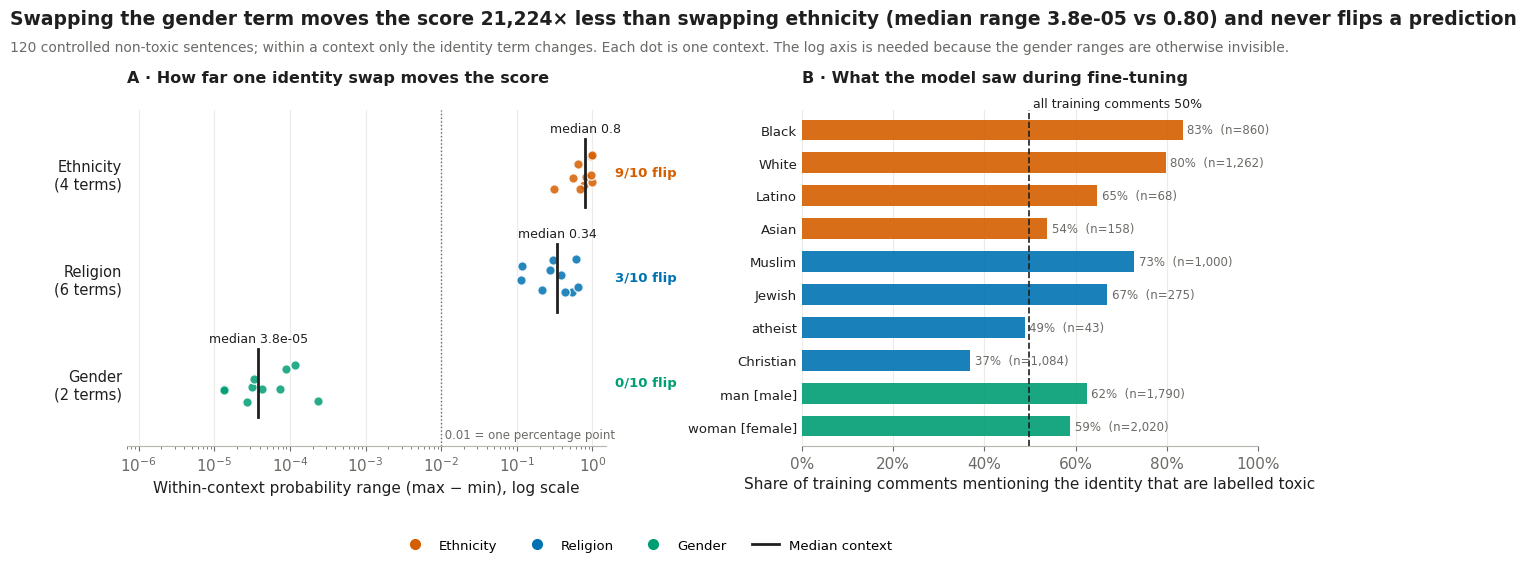


### Gender: almost no counterfactual effect

**What the data show.** Swapping “woman”, “man” inside otherwise identical non-toxic sentences changes the toxicity
probability by a median of **3.8e-05** and at most **2.3e-04**. All 20
gender variants stay far below the 0.5 threshold (median score 0.0006), so no prediction
changes. For comparison: ethnicity 0.804 (21,224× larger, 9/10 contexts flip); religion 0.339 (8,944× larger, 3/10 contexts flip). In decision terms, the gender term has no influence on this model in this
test set.

**Why this is not surprising for a Jigsaw-trained model.** The Jigsaw / Civil Comments data is the standard example
of *unintended identity bias* in toxicity classification. Dixon et al. (2018) showed that identity terms appeared
disproportionately often in toxic training comments, so the classifier learned the word itself as a toxicity cue,
and the Unintended Bias in Toxicity Classification challenge (Borkan et al., 2019) was built around exactly this
problem. The groups most often mis-associated with toxicity there are frequently attacked identities such as
*gay*, *Muslim*, *Jewish* and *Black*. Our result follows that pattern: the large shifts are in ethnicity and
religion, the gender shifts are negligible.

**Reasons the gender terms stay flat here**

1. **Training-data skew.** A fine-tuned classifier learns how often a word co-occurs with the toxic label.
   In the fine-tuning data, 50% of all comments are toxic. Comments annotated as mentioning ethnicity terms are toxic 79% of the time, religion terms are toxic 56% of the time, gender terms are toxic 61% of the time. The most skewed tested identity is **Black** (83% toxic, n=860). For gender, man [male] 62%, woman [female] 59% - which differs from the overall rate, so the training labels alone do not fully explain the flat gender result; reasons 2-5 below then carry more weight.
2. **The terms are everyday nouns.** Generic gender words appear in a very wide range of ordinary comments, so
   their association with any single label is diluted. A plausible further reason (not tested here) is that
   gendered abuse mostly uses slurs and insults rather than these neutral nouns, so the toxicity signal attaches to
   those other words.
3. **Only a binary pair was tested.** The set contains 2 terms per context. Gender identities that
   the Jigsaw literature flags as problematic (e.g. *transgender*) are not included, so this result cannot be
   generalised to gender identity as a whole.
4. **Scores sit at the floor.** The gender sentences score around 0.0006. Near 0 the probability
   scale compresses differences, so tiny shifts look like zero. Whatever happens on the logit scale, it does not
   come close to changing a decision.
5. **Different sentences per dimension and a small sample.** Each dimension uses its own 10 sentences, so part of
   the gap may come from how the gender sentences were written, and 10 contexts is limited evidence for an
   absence of effect. The gender check cell (8b) tests this with a cross-swap.

**Take-away.** On this controlled set the model is counterfactually stable for gender and unstable for ethnicity
and religion. This matches the known Jigsaw bias profile, but it does not show that the model is free of gender
bias in other terms, in borderline or toxic contexts, or in natural comments.

*References:* Dixon, L., Li, J., Sorensen, J., Thain, N., & Vasserman, L. (2018). Measuring and Mitigating
Unintended Bias in Text Classification. AIES. · Borkan, D., Dixon, L., Sorensen, J., Thain, N., & Vasserman, L.
(2019). Nuanced Metrics for Measuring Unintended Bias with Real Data for Text Classification. WWW Companion.


In [17]:
# =====================================================================================
# Gender terms barely move the model - evidence and explanation
# Run after section 8 (needs counterfactual_results, train_df, CLASSIFICATION_THRESHOLD).
#   Panel A  Within-context probability range per dimension on a log scale, so the gender
#            ranges (~1e-4) and the ethnicity ranges (~1e-1) are visible on one axis.
#   Panel B  How often training comments that mention each tested identity are toxic,
#            using the Jigsaw identity annotations in train_df. This is the data the model
#            learned its word-toxicity associations from.
#   Text     Data-driven summary plus the known Jigsaw identity-bias background.
# =====================================================================================

INK, MUTED, GRIDC = '#1f1f1f', '#6b6a66', '#ecebe6'
DIM_ORDER = ['ethnicity', 'religion', 'gender_term']
DIM_NAME = {'ethnicity': 'Ethnicity', 'religion': 'Religion', 'gender_term': 'Gender'}
_fallback = {'ethnicity': '#D55E00', 'religion': '#0072B2', 'gender_term': '#009E73'}
DIM_COLOR = {d: (COLORS.get(d) if 'COLORS' in globals() else None) or _fallback[d] for d in DIM_ORDER}
THR = float(CLASSIFICATION_THRESHOLD)
FLOOR = 1e-6                                              # log axis needs > 0

cf = counterfactual_results.copy()
cf['prob'] = cf['toxicity_probability'].astype(float)
dims = [d for d in DIM_ORDER if d in set(cf['dimension'])]

# ---- Per-context and per-dimension numbers -------------------------------------------
ctx = cf.groupby('template_id').agg(dimension=('dimension', 'first'), lo=('prob', 'min'), hi=('prob', 'max'),
                                    mean=('prob', 'mean'), variants=('prob', 'size'),
                                    flagged=('prob', lambda v: int((v >= THR).sum()))).reset_index()
ctx['range'] = ctx['hi'] - ctx['lo']
ctx['flip'] = (ctx['flagged'] > 0) & (ctx['flagged'] < ctx['variants'])
dim = ctx.groupby('dimension').agg(contexts=('template_id', 'size'), median_range=('range', 'median'),
                                   max_range=('range', 'max'), flips=('flip', 'sum'),
                                   median_level=('mean', 'median')).reindex(dims)
dim['flagged'] = cf.groupby('dimension')['prob'].apply(lambda v: int((v >= THR).sum())).reindex(dims)
dim['variants'] = cf.groupby('dimension').size().reindex(dims)
dim['terms'] = cf.groupby('dimension')['identity_term'].unique().reindex(dims)

# Guard: must match the notebook's verified dimension summary
_ds = counterfactual_dimension_summary.set_index('dimension')
for d in dims:
    assert np.isclose(dim.loc[d, 'median_range'], _ds.loc[d, 'median_context_probability_range'], atol=1e-9)
    assert int(dim.loc[d, 'flips']) == int(_ds.loc[d, 'contexts_with_label_flip'])

g = dim.loc['gender_term']
others = [d for d in dims if d != 'gender_term']
ratio = {d: dim.loc[d, 'median_range'] / max(g['median_range'], 1e-12) for d in others}

# ---- Training-data evidence: toxic share of comments mentioning each tested identity ---
TERM_TO_COL = {'woman': 'female', 'women': 'female', 'female': 'female', 'girl': 'female', 'girls': 'female',
               'man': 'male', 'men': 'male', 'male': 'male', 'boy': 'male', 'boys': 'male',
               'latina': 'latino', 'latinx': 'latino', 'hispanic': 'latino', 'gay': 'homosexual_gay_or_lesbian',
               'lesbian': 'homosexual_gay_or_lesbian'}
label_col = 'label' if 'label' in train_df.columns else None
base_rate = float(train_df[label_col].astype(int).mean()) if label_col else np.nan
train_rows = []
if label_col:
    for d in dims:
        for term in dim.loc[d, 'terms']:
            col = TERM_TO_COL.get(str(term).lower(), str(term).lower())
            if col not in train_df.columns:
                continue
            share = pd.to_numeric(train_df[col], errors='coerce')
            mention = share >= 0.5                            # same rule as the error analysis in section 2
            n = int(mention.sum())
            if n < 30:
                continue
            train_rows.append(dict(dimension=d, term=str(term), column=col, mentions=n,
                                   toxic_share=float(train_df.loc[mention, label_col].astype(int).mean())))
train_id = pd.DataFrame(train_rows)
if len(train_id):
    train_id['lift'] = train_id['toxic_share'] / base_rate
    train_id['model_mean_prob'] = train_id['term'].map(cf.groupby('identity_term')['prob'].mean())
    train_id['dim_rank'] = train_id['dimension'].map({d: i for i, d in enumerate(dims)})
    train_id = train_id.sort_values(['dim_rank', 'toxic_share'], ascending=[True, False]).reset_index(drop=True)

# ---- Figure ---------------------------------------------------------------------------
has_b = len(train_id) > 0
fig_gender, axes = plt.subplots(1, 2 if has_b else 1, figsize=(13, 5.6),
                                gridspec_kw={'width_ratios': [1.05, 1]} if has_b else None)
axA = axes[0] if has_b else axes

# Panel A · log-scale strip of within-context ranges
rng_ = np.random.default_rng(0)
for i, d in enumerate(dims):
    sub = ctx[ctx['dimension'] == d]
    y = i + rng_.uniform(-0.18, 0.18, len(sub))
    axA.scatter(np.maximum(sub['range'], FLOOR), y, s=46, color=DIM_COLOR[d], alpha=0.85,
                edgecolor='white', lw=1, zorder=3)
    med = max(dim.loc[d, 'median_range'], FLOOR)
    axA.plot([med, med], [i - 0.32, i + 0.32], color=INK, lw=2, zorder=4)
    axA.text(med, i - 0.36, f'median {dim.loc[d, "median_range"]:.2g}', ha='center', va='bottom',
             fontsize=9, color=INK)
    axA.text(1.02, i, f'{int(dim.loc[d, "flips"])}/{int(dim.loc[d, "contexts"])} flip',
             transform=axA.get_yaxis_transform(), ha='left', va='center', fontsize=9.5,
             color=DIM_COLOR[d], fontweight='bold')
axA.set_xscale('log')
axA.set_xlim(FLOOR * 0.7, 1.5)
axA.axvline(0.01, color=MUTED, lw=1, ls=':')
axA.text(0.01, len(dims) - 0.45, ' 0.01 = one percentage point', fontsize=8.5, color=MUTED, va='bottom')
axA.set_yticks(range(len(dims)))
axA.set_yticklabels([f'{DIM_NAME[d]}\n({len(dim.loc[d, "terms"])} terms)' for d in dims], fontsize=10.5, color=INK)
axA.set_ylim(len(dims) - 0.4, -0.6)
axA.set_xlabel('Within-context probability range (max − min), log scale')
axA.set_title('A · How far one identity swap moves the score', loc='left', fontsize=11.5, color=INK,
              fontweight='bold', pad=20)
axA.spines[['top', 'right', 'left']].set_visible(False)
axA.tick_params(axis='y', length=0)
axA.grid(axis='x', color=GRIDC, lw=0.8, which='major')
axA.set_axisbelow(True)

# Panel B · training-data toxic share per tested identity
if has_b:
    axB = axes[1]
    yb = np.arange(len(train_id))
    axB.barh(yb, train_id['toxic_share'], color=[DIM_COLOR[d] for d in train_id['dimension']], height=0.62,
             alpha=0.9)
    axB.axvline(base_rate, color=INK, lw=1.2, ls='--')
    axB.text(base_rate, 1.0, f' all training comments {base_rate:.0%}', fontsize=9, color=INK, va='bottom',
             transform=axB.get_xaxis_transform())
    for yy, r in zip(yb, train_id.itertuples()):
        axB.text(r.toxic_share + 0.01, yy, f'{r.toxic_share:.0%}  (n={r.mentions:,})', va='center', fontsize=8.5,
                 color=MUTED)
    axB.set_yticks(yb)
    axB.set_yticklabels([f'{r.term}' + (f' [{r.column}]' if r.column != r.term.lower() else '')
                         for r in train_id.itertuples()], fontsize=9.5, color=INK)
    axB.set_ylim(len(train_id) - 0.4, -0.6)
    axB.set_xlim(0, min(1.0, train_id['toxic_share'].max() + 0.22))
    axB.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
    axB.set_xlabel('Share of training comments mentioning the identity that are labelled toxic')
    axB.set_title('B · What the model saw during fine-tuning', loc='left', fontsize=11.5, color=INK,
                  fontweight='bold', pad=20)
    axB.spines[['top', 'right', 'left']].set_visible(False)
    axB.tick_params(axis='y', length=0)
    axB.grid(axis='x', color=GRIDC, lw=0.8)
    axB.set_axisbelow(True)

fig_gender.legend(handles=[Line2D([], [], marker='o', ls='', color=DIM_COLOR[d], ms=7, label=DIM_NAME[d])
                           for d in dims] + [Line2D([], [], color=INK, lw=2, label='Median context')],
                  loc='lower center', ncol=len(dims) + 1, frameon=False, fontsize=9.5, bbox_to_anchor=(0.5, -0.01))
lead = max(others, key=lambda d: dim.loc[d, 'median_range'])
fig_gender.suptitle(f'Swapping the gender term moves the score {ratio[lead]:,.0f}× less than swapping '
                    f'{DIM_NAME[lead].lower()} (median range {g["median_range"]:.1e} vs '
                    f'{dim.loc[lead, "median_range"]:.2f}) and never flips a prediction',
                    x=0.01, ha='left', fontsize=13.5, fontweight='bold', color=INK)
fig_gender.text(0.01, 0.905, f'{len(cf)} controlled non-toxic sentences; within a context only the identity term '
                'changes. Each dot is one context. The log axis is needed because the gender ranges are '
                'otherwise invisible.', fontsize=10, color=MUTED)
fig_gender.subplots_adjust(top=0.8, bottom=0.2, left=0.1, right=0.97, wspace=0.42)
plt.show()
if 'register_figure' in globals():
    register_figure('05d_gender_low_impact', fig_gender)

# ---- Text -----------------------------------------------------------------------------
g_terms = ', '.join(f'“{t}”' for t in g['terms'])
ratio_txt = '; '.join(f'{DIM_NAME[d].lower()} {dim.loc[d, "median_range"]:.3f} '
                      f'({ratio[d]:,.0f}× larger, {int(dim.loc[d, "flips"])}/{int(dim.loc[d, "contexts"])} contexts flip)'
                      for d in others)

if has_b:
    def share_of(d):
        t = train_id[train_id['dimension'] == d]
        return (t['toxic_share'] * t['mentions']).sum() / t['mentions'].sum() if len(t) else np.nan
    g_tr = train_id[train_id['dimension'] == 'gender_term']
    most = train_id.sort_values('toxic_share', ascending=False).iloc[0]
    data_txt = (
        f'In the fine-tuning data, {base_rate:.0%} of all comments are toxic. Comments annotated as mentioning '
        + ', '.join(f'{DIM_NAME[d].lower()} terms are toxic {share_of(d):.0%} of the time' for d in dims if np.isfinite(share_of(d)))
        + f'. The most skewed tested identity is **{most.term}** ({most.toxic_share:.0%} toxic, n={most.mentions:,}). '
        + (('For gender, ' + ', '.join(f'{r.term} [{r.column}] {r.toxic_share:.0%}' for r in g_tr.itertuples())
            + ' - ' + ('close to the overall rate, so the label gives the model little reason to treat these words '
                       'as a toxicity cue.' if (abs(g_tr['toxic_share'] - base_rate) < 0.1).all() else
                       'which differs from the overall rate, so the training labels alone do not fully explain the '
                       'flat gender result; reasons 2-5 below then carry more weight.'))
           if len(g_tr) else 'The gender terms could not be matched to an identity column.')
    )
else:
    data_txt = ('The Jigsaw identity columns were not found in `train_df`, so the training-data comparison '
                'is skipped.')

display(Markdown(f"""
### Gender: almost no counterfactual effect

**What the data show.** Swapping {g_terms} inside otherwise identical non-toxic sentences changes the toxicity
probability by a median of **{g['median_range']:.1e}** and at most **{g['max_range']:.1e}**. All {int(g['variants'])}
gender variants stay far below the {THR:g} threshold (median score {g['median_level']:.4f}), so no prediction
changes. For comparison: {ratio_txt}. In decision terms, the gender term has no influence on this model in this
test set.

**Why this is not surprising for a Jigsaw-trained model.** The Jigsaw / Civil Comments data is the standard example
of *unintended identity bias* in toxicity classification. Dixon et al. (2018) showed that identity terms appeared
disproportionately often in toxic training comments, so the classifier learned the word itself as a toxicity cue,
and the Unintended Bias in Toxicity Classification challenge (Borkan et al., 2019) was built around exactly this
problem. The groups most often mis-associated with toxicity there are frequently attacked identities such as
*gay*, *Muslim*, *Jewish* and *Black*. Our result follows that pattern: the large shifts are in ethnicity and
religion, the gender shifts are negligible.

**Reasons the gender terms stay flat here**

1. **Training-data skew.** A fine-tuned classifier learns how often a word co-occurs with the toxic label.
   {data_txt}
2. **The terms are everyday nouns.** Generic gender words appear in a very wide range of ordinary comments, so
   their association with any single label is diluted. A plausible further reason (not tested here) is that
   gendered abuse mostly uses slurs and insults rather than these neutral nouns, so the toxicity signal attaches to
   those other words.
3. **Only a binary pair was tested.** The set contains {len(g['terms'])} terms per context. Gender identities that
   the Jigsaw literature flags as problematic (e.g. *transgender*) are not included, so this result cannot be
   generalised to gender identity as a whole.
4. **Scores sit at the floor.** The gender sentences score around {g['median_level']:.4f}. Near 0 the probability
   scale compresses differences, so tiny shifts look like zero. Whatever happens on the logit scale, it does not
   come close to changing a decision.
5. **Different sentences per dimension and a small sample.** Each dimension uses its own 10 sentences, so part of
   the gap may come from how the gender sentences were written, and 10 contexts is limited evidence for an
   absence of effect. The gender check cell (8b) tests this with a cross-swap.

**Take-away.** On this controlled set the model is counterfactually stable for gender and unstable for ethnicity
and religion. This matches the known Jigsaw bias profile, but it does not show that the model is free of gender
bias in other terms, in borderline or toxic contexts, or in natural comments.

*References:* Dixon, L., Li, J., Sorensen, J., Thain, N., & Vasserman, L. (2018). Measuring and Mitigating
Unintended Bias in Text Classification. AIES. · Borkan, D., Dixon, L., Sorensen, J., Thain, N., & Vasserman, L.
(2019). Nuanced Metrics for Measuring Unintended Bias with Real Data for Text Classification. WWW Companion.
"""))

## 6. Automatically generated answers to the research questions

The next cell derives the numbers from the current run. If the model or split changes, the written answer updates with the result tables instead of silently retaining old values.


In [18]:
performance_lookup = numeric_frame(performance_table, ['value']).set_index('metric')['value'].to_dict()
cm = numeric_frame(confusion_table, ['count']).set_index('error_or_result')['count'].astype(int).to_dict()
confidence_lookup = (
    numeric_frame(
        confidence_by_correctness,
        ['cases', 'mean_confidence', 'median_confidence'],
    )
    .set_index('correctness')
)

false_positive_rate = cm['False positives'] / (cm['False positives'] + cm['True negatives'])
false_negative_rate = cm['False negatives'] / (cm['False negatives'] + cm['True positives'])
high_confidence_errors = int((errors['prediction_confidence'] >= 0.95).sum())
high_confidence_error_share = high_confidence_errors / len(errors)

context_flips = int(counterfactual_template_summary['label_flip'].astype(bool).sum())
neutral_toxic = int(counterfactual_results['predicted_label'].sum())
mean_context_range = pd.to_numeric(counterfactual_template_summary['probability_range']).mean()
maximum_context = counterfactual_template_summary.loc[
    pd.to_numeric(counterfactual_template_summary['probability_range']).idxmax()
]

dimension_answers = numeric_frame(
    counterfactual_dimension_summary,
    [
        'mean_context_probability_range',
        'mean_context_pairwise_absolute_difference',
        'contexts_with_label_flip',
        'templates',
    ],
).set_index('dimension')

answer_text = f'''
### Direct answers

1. **Held-out performance.** The model reaches **{performance_lookup['Accuracy']:.2%} accuracy**, **{performance_lookup['Precision']:.2%} precision**, **{performance_lookup['Recall']:.2%} recall**, **{performance_lookup['F1']:.2%} F1**, and **{performance_lookup['ROC AUC']:.2%} ROC AUC** on **{len(test_analysis):,}** held-out comments.

2. **Error asymmetry.** It produces **{cm['False positives']:,} false positives** and **{cm['False negatives']:,} false negatives**. Thus, false positives are more frequent. The false-positive rate is **{false_positive_rate:.2%}**, compared with a false-negative rate of **{false_negative_rate:.2%}**.

3. **Confidence.** Mean confidence is **{confidence_lookup.loc['Correct', 'mean_confidence']:.3f}** for correct predictions and **{confidence_lookup.loc['Incorrect', 'mean_confidence']:.3f}** for errors. Yet **{high_confidence_errors:,} of {len(errors):,} errors ({high_confidence_error_share:.1%})** still have confidence of at least 0.95. High confidence therefore does not guarantee correctness.

4. **Counterfactual stability.** **{neutral_toxic} of {len(counterfactual_results)} neutral variants ({neutral_toxic / len(counterfactual_results):.2%})** are classified as toxic. **{context_flips} of {len(counterfactual_template_summary)} contexts ({context_flips / len(counterfactual_template_summary):.1%})** contain a label flip. The mean within-context probability range is **{mean_context_range:.3f}**.

5. **Where differences concentrate.** Mean pairwise differences are largest for **ethnicity ({dimension_answers.loc['ethnicity', 'mean_context_pairwise_absolute_difference']:.3f})**, followed by **religion ({dimension_answers.loc['religion', 'mean_context_pairwise_absolute_difference']:.3f})**, and are negligible for **gender terms ({dimension_answers.loc['gender_term', 'mean_context_pairwise_absolute_difference']:.5f})**. The largest single context range is **{float(maximum_context['probability_range']):.3f}** for `{maximum_context['template_id']}`: *{maximum_context['sentence_template']}*

### Main conclusion

The fine-tuned classifier performs strongly on the held-out Jigsaw split, but it is **not counterfactually stable across all identity-only substitutions**. The strongest and most systematic score changes occur in the ethnicity and religion tests. Aggregate predictive performance and identity-term stability are therefore separate properties of the model.
'''
display(Markdown(textwrap.dedent(answer_text) if 'textwrap' in globals() else answer_text))



### Direct answers

1. **Held-out performance.** The model reaches **95.04% accuracy**, **94.27% precision**, **96.07% recall**, **95.16% F1**, and **98.97% ROC AUC** on **18,149** held-out comments.

2. **Error asymmetry.** It produces **538 false positives** and **362 false negatives**. Thus, false positives are more frequent. The false-positive rate is **6.02%**, compared with a false-negative rate of **3.93%**.

3. **Confidence.** Mean confidence is **0.988** for correct predictions and **0.882** for errors. Yet **432 of 900 errors (48.0%)** still have confidence of at least 0.95. High confidence therefore does not guarantee correctness.

4. **Counterfactual stability.** **13 of 120 neutral variants (10.83%)** are classified as toxic. **12 of 30 contexts (40.0%)** contain a label flip. The mean within-context probability range is **0.377**.

5. **Where differences concentrate.** Mean pairwise differences are largest for **ethnicity (0.413)**, followed by **religion (0.121)**, and are negligible for **gender terms (0.00007)**. The largest single context range is **0.980** for `ETH_08`: *The {identity} customer requested more information.*

### Main conclusion

The fine-tuned classifier performs strongly on the held-out Jigsaw split, but it is **not counterfactually stable across all identity-only substitutions**. The strongest and most systematic score changes occur in the ethnicity and religion tests. Aggregate predictive performance and identity-term stability are therefore separate properties of the model.


## Interpretation limits and lecture-note links

- The controlled set contains only **10 synthetic neutral contexts per identity dimension**. It demonstrates counterfactual sensitivity; it does not estimate its prevalence in natural language.
- The dimensions use different contexts and different numbers of terms. Cross-dimension comparisons are therefore descriptive. The mean pairwise absolute difference is more comparable than the raw range, but it does not remove all design differences.
- The observed probability differences describe the model's behavior. They do not identify which internal representation caused the behavior.
- These figures are **post-hoc behavioral analyses**, combining global summaries with local controlled cases. They are not token attributions, LIME explanations, SHAP values, or causal effects.
- PCA, UMAP, t-SNE, hidden-state embeddings, and token-attribution methods belong to Phase II. Lecture 03, slides 6 and 20–26, also warns that projections can hide distortion and create false visual confidence.

### Suggested lecture references in the report

- **Lecture 01, slide 12:** Phase I asks *how the model behaves*; Phase II asks *what the model learned*.
- **Lecture 02, slides 7–10:** show distributions and design every figure for a concrete analytical task.
- **Lecture 02, slide 15:** maximize data-ink and remove decorative elements that do not support the question.
- **Lecture 02, slides 38–39:** use Gestalt connection only for true pairs or groups.
- **Lecture 02, slides 43–44:** aligned simultaneous views reduce reliance on memory—“eyes beat memory.”
- **Lecture 02, slides 54–59:** keep base rates, counts, and denominators visible.
- **Lecture 04, slide 11:** vary the input and visualize how the model response changes.
- **Lecture 04, slides 20–23:** ICE/c-ICE motivates showing heterogeneous responses and their distributions.
- **Lecture 03, slides 6 and 20–26:** defer projection-based representation analysis to Phase II and interpret it cautiously.


In [19]:
# ------------------------------------------------------------
# Prepare values from the current notebook results
# ------------------------------------------------------------

performance = performance_table.copy()
performance["value"] = pd.to_numeric(performance["value"])
performance = performance.set_index("metric")["value"]

confusion = confusion_table.copy()
confusion["count"] = pd.to_numeric(confusion["count"]).astype(int)
confusion = confusion.set_index("error_or_result")["count"]

confidence = confidence_by_correctness.copy()
for column in ["cases", "mean_confidence", "median_confidence"]:
    confidence[column] = pd.to_numeric(confidence[column])
confidence = confidence.set_index("correctness")

test_errors = errors.copy()
test_errors["prediction_confidence"] = pd.to_numeric(
    test_errors["prediction_confidence"]
)

counterfactual = counterfactual_results.copy()
counterfactual["toxicity_probability"] = pd.to_numeric(
    counterfactual["toxicity_probability"]
)
counterfactual["predicted_label"] = pd.to_numeric(
    counterfactual["predicted_label"]
).astype(int)

contexts = counterfactual_template_summary.copy()
for column in [
    "probability_range",
    "minimum_probability",
    "maximum_probability",
]:
    contexts[column] = pd.to_numeric(contexts[column])

if contexts["label_flip"].dtype == bool:
    context_flip = contexts["label_flip"]
else:
    context_flip = (
        contexts["label_flip"]
        .astype(str)
        .str.lower()
        .isin(["true", "1", "yes"])
    )

dimensions = counterfactual_dimension_summary.copy()
numeric_dimension_columns = [
    "templates",
    "mean_context_probability_range",
    "mean_context_pairwise_absolute_difference",
    "contexts_with_label_flip",
    "neutral_variations_predicted_toxic",
    "toxic_prediction_rate",
]

for column in numeric_dimension_columns:
    dimensions[column] = pd.to_numeric(dimensions[column])

dimensions = dimensions.set_index("dimension")

# ------------------------------------------------------------
# Calculate additional values
# ------------------------------------------------------------

false_positive_rate = (
    confusion["False positives"]
    / (confusion["False positives"] + confusion["True negatives"])
)

false_negative_rate = (
    confusion["False negatives"]
    / (confusion["False negatives"] + confusion["True positives"])
)

errors_at_95 = int(
    (test_errors["prediction_confidence"] >= 0.95).sum()
)

errors_at_99 = int(
    (test_errors["prediction_confidence"] >= 0.99).sum()
)

neutral_toxic = int(counterfactual["predicted_label"].sum())
number_of_variants = len(counterfactual)

contexts_with_flip = int(context_flip.sum())
number_of_contexts = len(contexts)

mean_context_range = contexts["probability_range"].mean()

largest_context = contexts.loc[
    contexts["probability_range"].idxmax()
]

term_means = (
    counterfactual
    .groupby(["dimension", "identity_term"])["toxicity_probability"]
    .mean()
)

highest_ethnicity_term = term_means.loc["ethnicity"].idxmax()
highest_religion_term = term_means.loc["religion"].idxmax()

# ------------------------------------------------------------
# Generate the research-question report
# ------------------------------------------------------------

research_question_report = f"""
# Research questions and evidence-based answers

## Main research question

**How does the fine-tuned BERT classifier behave on held-out Jigsaw
comments, and how stable are its toxicity probabilities when only
identity-related terms are changed in otherwise identical, non-toxic
sentences?**

The classifier performs strongly on the held-out Jigsaw test set,
reaching **{performance["Accuracy"]:.2%} accuracy** and an ROC AUC of
**{performance["ROC AUC"]:.2%}**. However, the controlled identity-term
tests show that strong aggregate performance does not imply
counterfactual stability.

Across {number_of_variants} neutral identity variations,
**{neutral_toxic} examples ({neutral_toxic / number_of_variants:.2%})**
are classified as toxic. Furthermore,
**{contexts_with_flip} of {number_of_contexts} sentence contexts
({contexts_with_flip / number_of_contexts:.1%})** contain at least one
classification change when only the identity term is replaced.

**Evidence:** Visualisation 1 provides the aggregate performance
overview. Visualisations 3–5 show the identity-related probability
changes. The underlying data are stored in `performance_table`,
`counterfactual_results`, `counterfactual_template_summary`, and
`counterfactual_dimension_summary`.

---

## Subquestion 1

**How accurately does the classifier distinguish toxic from non-toxic
comments on the held-out test set?**

The model achieves:

- **Accuracy:** {performance["Accuracy"]:.2%}
- **Precision:** {performance["Precision"]:.2%}
- **Recall:** {performance["Recall"]:.2%}
- **F1 score:** {performance["F1"]:.2%}
- **ROC AUC:** {performance["ROC AUC"]:.2%}

These results indicate strong classification performance on the
held-out test split. They describe performance on this particular
nearly balanced test set and should not automatically be interpreted
as expected performance under a different real-world prevalence.

**Evidence:** Visualisation 1 — *Aggregate performance and confusion
matrix*. Data: `performance_table` and `confusion_table`.

---

## Subquestion 2

**Does the model produce more false positives or false negatives?**

The classifier produces **{confusion["False positives"]:,} false
positives** and **{confusion["False negatives"]:,} false negatives**.
It therefore makes **{confusion["False positives"] - confusion["False negatives"]:,}
more false-positive errors**.

The false-positive rate is **{false_positive_rate:.2%}**, compared with
a false-negative rate of **{false_negative_rate:.2%}**. The model is
therefore more likely to incorrectly flag a non-toxic comment as toxic
than to miss a toxic comment on this test set.

**Evidence:** Visualisation 1 — *Confusion matrix*.  
Data: `confusion_table` and `test_analysis`.

---

## Subquestion 3

**How confident is the model when its predictions are correct or
incorrect?**

Mean confidence is **{confidence.loc["Correct", "mean_confidence"]:.3f}**
for correct predictions and
**{confidence.loc["Incorrect", "mean_confidence"]:.3f}** for incorrect
predictions. Confidence is therefore informative on average.

Nevertheless, **{errors_at_95:,} of {len(test_errors):,} errors
({errors_at_95 / len(test_errors):.1%})** have confidence of at least
0.95, and **{errors_at_99:,} errors
({errors_at_99 / len(test_errors):.1%})** have confidence of at least
0.99. High confidence therefore does not guarantee that an individual
prediction is correct.

**Evidence:** Visualisation 2 — *Confidence distribution and error rate
by confidence bin*. Data: `confidence_by_correctness`,
`confidence_by_bin`, and `errors`.

---

## Subquestion 4

**How much do toxicity probabilities vary within controlled
identity-term sets?**

The mean probability range within one otherwise identical sentence
context is **{mean_context_range:.3f}**. The largest observed range is
**{largest_context["probability_range"]:.3f}**.

In the most sensitive context —  
*“{largest_context["sentence_template"]}”* — the probability ranges
from **{largest_context["minimum_probability"]:.3f}** for
**{largest_context["minimum_probability_identity_term"]}** to
**{largest_context["maximum_probability"]:.3f}** for
**{largest_context["maximum_probability_identity_term"]}**.

The fact that {contexts_with_flip} contexts cross the decision threshold
shows that identity substitutions can change not only the probability
but also the final predicted class.

**Evidence:** Visualisation 3 — *Identity-swap stability atlas* and
Visualisation 4 — *Largest identity-only probability shifts*.  
Data: `counterfactual_results` and
`counterfactual_template_summary`.

---

## Subquestion 5

**Are larger probability differences concentrated in particular
sentence contexts or identity dimensions?**

Yes. The mean pairwise absolute probability difference is:

- **Ethnicity:** {dimensions.loc["ethnicity", "mean_context_pairwise_absolute_difference"]:.3f}
- **Religion:** {dimensions.loc["religion", "mean_context_pairwise_absolute_difference"]:.3f}
- **Gender terms:** {dimensions.loc["gender_term", "mean_context_pairwise_absolute_difference"]:.5f}

Ethnicity therefore shows the strongest counterfactual sensitivity,
followed by religion. Gender-term substitutions are almost completely
stable in this controlled set.

The term with the highest mean probability across the ethnicity
contexts is **{highest_ethnicity_term}**, while the highest-scoring term
across the religion contexts is **{highest_religion_term}**. The
largest differences are therefore not distributed evenly across all
terms or contexts.

**Evidence:** Visualisation 3 — *Identity-swap stability atlas*,
Visualisation 4 — *Largest identity-only probability shifts*, and
Visualisation 5 — *Context-centred identity-term effects*.  
Data: `counterfactual_results`,
`counterfactual_dimension_summary`, and `identity_term_summary`.

---

## Overall conclusion

The fine-tuned BERT classifier distinguishes toxic from non-toxic
comments accurately on the held-out Jigsaw test set. However, its
toxicity probabilities are not equally stable under controlled
identity-only substitutions. The strongest and most systematic changes
occur in the ethnicity and religion tests.

The results therefore demonstrate that **aggregate predictive
performance and counterfactual identity-term stability are separate
properties of the model**.

These findings describe this model's behavior on a small controlled set
of synthetic, non-toxic sentences. They demonstrate counterfactual
sensitivity but do not estimate how frequently such behavior occurs in
all natural language or establish a causal explanation of the model's
internal representations.
"""

display(Markdown(textwrap.dedent(research_question_report)))


# Research questions and evidence-based answers

## Main research question

**How does the fine-tuned BERT classifier behave on held-out Jigsaw
comments, and how stable are its toxicity probabilities when only
identity-related terms are changed in otherwise identical, non-toxic
sentences?**

The classifier performs strongly on the held-out Jigsaw test set,
reaching **95.04% accuracy** and an ROC AUC of
**98.97%**. However, the controlled identity-term
tests show that strong aggregate performance does not imply
counterfactual stability.

Across 120 neutral identity variations,
**13 examples (10.83%)**
are classified as toxic. Furthermore,
**12 of 30 sentence contexts
(40.0%)** contain at least one
classification change when only the identity term is replaced.

**Evidence:** Visualisation 1 provides the aggregate performance
overview. Visualisations 3–5 show the identity-related probability
changes. The underlying data are stored in `performance_table`,
`counterfactual_results`, `counterfactual_template_summary`, and
`counterfactual_dimension_summary`.

---

## Subquestion 1

**How accurately does the classifier distinguish toxic from non-toxic
comments on the held-out test set?**

The model achieves:

- **Accuracy:** 95.04%
- **Precision:** 94.27%
- **Recall:** 96.07%
- **F1 score:** 95.16%
- **ROC AUC:** 98.97%

These results indicate strong classification performance on the
held-out test split. They describe performance on this particular
nearly balanced test set and should not automatically be interpreted
as expected performance under a different real-world prevalence.

**Evidence:** Visualisation 1 — *Aggregate performance and confusion
matrix*. Data: `performance_table` and `confusion_table`.

---

## Subquestion 2

**Does the model produce more false positives or false negatives?**

The classifier produces **538 false
positives** and **362 false negatives**.
It therefore makes **176
more false-positive errors**.

The false-positive rate is **6.02%**, compared with
a false-negative rate of **3.93%**. The model is
therefore more likely to incorrectly flag a non-toxic comment as toxic
than to miss a toxic comment on this test set.

**Evidence:** Visualisation 1 — *Confusion matrix*.  
Data: `confusion_table` and `test_analysis`.

---

## Subquestion 3

**How confident is the model when its predictions are correct or
incorrect?**

Mean confidence is **0.988**
for correct predictions and
**0.882** for incorrect
predictions. Confidence is therefore informative on average.

Nevertheless, **432 of 900 errors
(48.0%)** have confidence of at least
0.95, and **181 errors
(20.1%)** have confidence of at least
0.99. High confidence therefore does not guarantee that an individual
prediction is correct.

**Evidence:** Visualisation 2 — *Confidence distribution and error rate
by confidence bin*. Data: `confidence_by_correctness`,
`confidence_by_bin`, and `errors`.

---

## Subquestion 4

**How much do toxicity probabilities vary within controlled
identity-term sets?**

The mean probability range within one otherwise identical sentence
context is **0.377**. The largest observed range is
**0.980**.

In the most sensitive context —  
*“The {identity} customer requested more information.”* — the probability ranges
from **0.001** for
**Asian** to
**0.981** for
**Black**.

The fact that 12 contexts cross the decision threshold
shows that identity substitutions can change not only the probability
but also the final predicted class.

**Evidence:** Visualisation 3 — *Identity-swap stability atlas* and
Visualisation 4 — *Largest identity-only probability shifts*.  
Data: `counterfactual_results` and
`counterfactual_template_summary`.

---

## Subquestion 5

**Are larger probability differences concentrated in particular
sentence contexts or identity dimensions?**

Yes. The mean pairwise absolute probability difference is:

- **Ethnicity:** 0.413
- **Religion:** 0.121
- **Gender terms:** 0.00007

Ethnicity therefore shows the strongest counterfactual sensitivity,
followed by religion. Gender-term substitutions are almost completely
stable in this controlled set.

The term with the highest mean probability across the ethnicity
contexts is **Black**, while the highest-scoring term
across the religion contexts is **Muslim**. The
largest differences are therefore not distributed evenly across all
terms or contexts.

**Evidence:** Visualisation 3 — *Identity-swap stability atlas*,
Visualisation 4 — *Largest identity-only probability shifts*, and
Visualisation 5 — *Context-centred identity-term effects*.  
Data: `counterfactual_results`,
`counterfactual_dimension_summary`, and `identity_term_summary`.

---

## Overall conclusion

The fine-tuned BERT classifier distinguishes toxic from non-toxic
comments accurately on the held-out Jigsaw test set. However, its
toxicity probabilities are not equally stable under controlled
identity-only substitutions. The strongest and most systematic changes
occur in the ethnicity and religion tests.

The results therefore demonstrate that **aggregate predictive
performance and counterfactual identity-term stability are separate
properties of the model**.

These findings describe this model's behavior on a small controlled set
of synthetic, non-toxic sentences. They demonstrate counterfactual
sensitivity but do not estimate how frequently such behavior occurs in
all natural language or establish a causal explanation of the model's
internal representations.


In [20]:
# Exports every chart registered with register_figure(): Plotly figures as interactive HTML,
# matplotlib figures as PNG. Run the chart cells above first.
assert EXPORT_FIGURES, 'No figures registered - run the visualisation cells above first.'

export_folder = Path("/kaggle/working/phase1_visualizations")
export_folder.mkdir(parents=True, exist_ok=True)
for old_file in list(export_folder.glob("*.html")) + list(export_folder.glob("*.png")):
    old_file.unlink()                                   # no stale charts from earlier runs

exported = []
for filename, figure in sorted(EXPORT_FIGURES.items()):
    if hasattr(figure, "write_html"):                   # Plotly
        target = export_folder / f"{filename}.html"
        figure.write_html(target, include_plotlyjs=True, full_html=True)
    else:                                               # matplotlib
        target = export_folder / f"{filename}.png"
        figure.savefig(target, dpi=200, bbox_inches="tight", facecolor="white")
    exported.append(target)

zip_path = Path("/kaggle/working/phase1_visualizations.zip")
with zipfile.ZipFile(zip_path, mode="w", compression=zipfile.ZIP_DEFLATED) as archive:
    for chart_file in exported:
        archive.write(chart_file, arcname=chart_file.name)

print(f"Export created: {zip_path} ({len(exported)} charts)")
for chart_file in exported:
    print("  -", chart_file.name)


Export created: /kaggle/working/phase1_visualizations.zip (12 charts)
  - 01a_performance_overview.html
  - 01b_score_distribution.png
  - 02a_confidence_analysis.html
  - 02b_error_types.png
  - 02c_threshold_tradeoff.png
  - 02d_identity_false_positives.png
  - 03_confidence_calibration.png
  - 04_largest_probability_shifts.html
  - 05a_context_centred_effects.html
  - 05b_identity_term_heatmap.png
  - 05c_centred_term_effects.png
  - 05d_gender_low_impact.png
